## 1. Setup

In [1]:
from pathlib import Path
from itertools import combinations

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from scipy.stats import ks_2samp
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 100)

### Project configuration

In [2]:
ROOT = Path.cwd()
while not (ROOT / "config" / "config.yaml").is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find config/config.yaml")
    ROOT = ROOT.parent

CONFIG_PATH = ROOT / "config" / "config.yaml"
with CONFIG_PATH.open(encoding="utf-8") as file:
    cfg = yaml.safe_load(file)

# Parquet v3 directory confirmed in the repository tree: data/parquet/v3.
PARQUET_DIR = ROOT / cfg["paths"]["parquet_dir"] / "v3"
assert PARQUET_DIR.is_dir(), f"Missing Parquet directory: {PARQUET_DIR}"
TIME_COLS = ["FLOW_START_MILLISECONDS", "FLOW_END_MILLISECONDS"]
BYTE_RATE_COLS = ["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]
IAT_COLS = ["SRC_TO_DST_IAT_MIN", "SRC_TO_DST_IAT_MAX", "SRC_TO_DST_IAT_AVG", "SRC_TO_DST_IAT_STDDEV",
            "DST_TO_SRC_IAT_MIN", "DST_TO_SRC_IAT_MAX", "DST_TO_SRC_IAT_AVG", "DST_TO_SRC_IAT_STDDEV"]
DUCKDB_CONFIG = cfg["duckdb"]
print(f"Project root: {ROOT}")
print(f"Parquet directory: {PARQUET_DIR}")

Project root: /home/luca-zerella/Scrivania/intrusion_detection
Parquet directory: /home/luca-zerella/Scrivania/intrusion_detection/data/parquet/v3


### DuckDB connection

In [3]:
THREADS = 3  # Easy-to-edit thread limit
con = duckdb.connect()
con.execute(f"PRAGMA threads={THREADS}")
con.execute(f"PRAGMA memory_limit='{DUCKDB_CONFIG['memory_limit']}'")
temp_directory = (ROOT / DUCKDB_CONFIG["temp_directory"]).resolve()
temp_directory.mkdir(parents=True, exist_ok=True)
temp_sql_path = str(temp_directory).replace("'", "''")
con.execute(f"PRAGMA temp_directory='{temp_sql_path}'")

parquet_glob = str(PARQUET_DIR / "*.parquet").replace("'", "''")
con.execute(f"CREATE OR REPLACE VIEW flows AS SELECT * FROM read_parquet('{parquet_glob}')")

def q(sql):
    return con.execute(sql).df()

def sql_ident(name):
    return '"' + str(name).replace('"', '""') + '"'

def show_plot(fig):
    fig.tight_layout()
    plt.show()

print("DuckDB connection and flows view are ready.")

DuckDB connection and flows view are ready.


## 2. Dataset structure

In [4]:
schema = q("DESCRIBE flows")
ALL_COLUMNS = schema["column_name"].tolist()
print(f"Columns: {len(ALL_COLUMNS)}")
display(schema)

Columns: 57


,column_name,column_type,null,key,default,extra
0,row_id,BIGINT,YES,None,None,None
1,Dataset,VARCHAR,YES,None,None,None
2,FLOW_START_MILLISECONDS,BIGINT,YES,None,None,None
3,FLOW_END_MILLISECONDS,BIGINT,YES,None,None,None
4,IPV4_SRC_ADDR,VARCHAR,YES,None,None,None
5,L4_SRC_PORT,INTEGER,YES,None,None,None
6,IPV4_DST_ADDR,VARCHAR,YES,None,None,None
7,L4_DST_PORT,INTEGER,YES,None,None,None
8,PROTOCOL,INTEGER,YES,None,None,None
9,L7_PROTO,DOUBLE,YES,None,None,None


In [5]:
total_rows = int(q("SELECT COUNT(*) AS total_rows FROM flows").iloc[0]["total_rows"])
rows_by_dataset = q("SELECT Dataset, COUNT(*) AS rows FROM flows GROUP BY Dataset ORDER BY Dataset")
print(f"Total rows: {total_rows:,}")
display(rows_by_dataset)
# Full-table row counts are useful for comparison with the official dataset counts.

Total rows: 66,935,021


,Dataset,rows
0,NF-BoT-IoT,16933808
1,NF-CSE-CIC-IDS2018,20115529
2,NF-ToN-IoT,27520260
3,NF-UNSW-NB15,2365424


In [6]:
TYPES = {
    "FLOW_START_MILLISECONDS": "BIGINT", "FLOW_END_MILLISECONDS": "BIGINT", "IPV4_SRC_ADDR": "VARCHAR", "L4_SRC_PORT": "INTEGER",
    "IPV4_DST_ADDR": "VARCHAR", "L4_DST_PORT": "INTEGER", "PROTOCOL": "INTEGER", "L7_PROTO": "DOUBLE", "IN_BYTES": "BIGINT",
    "IN_PKTS": "BIGINT", "OUT_BYTES": "BIGINT", "OUT_PKTS": "BIGINT", "TCP_FLAGS": "INTEGER", "CLIENT_TCP_FLAGS": "INTEGER",
    "SERVER_TCP_FLAGS": "INTEGER", "FLOW_DURATION_MILLISECONDS": "BIGINT", "DURATION_IN": "BIGINT", "DURATION_OUT": "BIGINT",
    "MIN_TTL": "INTEGER", "MAX_TTL": "INTEGER", "LONGEST_FLOW_PKT": "INTEGER", "SHORTEST_FLOW_PKT": "INTEGER", "MIN_IP_PKT_LEN": "INTEGER",
    "MAX_IP_PKT_LEN": "INTEGER", "SRC_TO_DST_SECOND_BYTES": "DOUBLE", "DST_TO_SRC_SECOND_BYTES": "DOUBLE", "RETRANSMITTED_IN_BYTES": "BIGINT",
    "RETRANSMITTED_IN_PKTS": "BIGINT", "RETRANSMITTED_OUT_BYTES": "BIGINT", "RETRANSMITTED_OUT_PKTS": "BIGINT", "SRC_TO_DST_AVG_THROUGHPUT": "BIGINT",
    "DST_TO_SRC_AVG_THROUGHPUT": "BIGINT", "NUM_PKTS_UP_TO_128_BYTES": "BIGINT", "NUM_PKTS_128_TO_256_BYTES": "BIGINT", "NUM_PKTS_256_TO_512_BYTES": "BIGINT",
    "NUM_PKTS_512_TO_1024_BYTES": "BIGINT", "NUM_PKTS_1024_TO_1514_BYTES": "BIGINT", "TCP_WIN_MAX_IN": "INTEGER", "TCP_WIN_MAX_OUT": "INTEGER",
    "ICMP_TYPE": "INTEGER", "ICMP_IPV4_TYPE": "INTEGER", "DNS_QUERY_ID": "INTEGER", "DNS_QUERY_TYPE": "INTEGER", "DNS_TTL_ANSWER": "BIGINT",
    "FTP_COMMAND_RET_CODE": "INTEGER", "SRC_TO_DST_IAT_MIN": "BIGINT", "SRC_TO_DST_IAT_MAX": "BIGINT", "SRC_TO_DST_IAT_AVG": "DOUBLE",
    "SRC_TO_DST_IAT_STDDEV": "DOUBLE", "DST_TO_SRC_IAT_MIN": "BIGINT", "DST_TO_SRC_IAT_MAX": "BIGINT", "DST_TO_SRC_IAT_AVG": "DOUBLE",
    "DST_TO_SRC_IAT_STDDEV": "DOUBLE", "Label": "INTEGER", "Attack": "VARCHAR",
}
EXPECTED_COLUMNS = ["row_id", *TYPES, "Dataset"]
missing_columns = sorted(set(EXPECTED_COLUMNS) - set(ALL_COLUMNS))
extra_columns = sorted(set(ALL_COLUMNS) - set(EXPECTED_COLUMNS))
print("Missing expected columns")
display(pd.DataFrame({"column": missing_columns}))
print("Extra columns")
display(pd.DataFrame({"column": extra_columns}))
found_types = dict(zip(schema["column_name"], schema["column_type"].str.upper()))
type_rows = [{"column": name, "expected": expected, "found": found_types.get(name), "ok": found_types.get(name) == expected}
             for name, expected in TYPES.items()]
type_rows.extend({"column": name, "expected": "<extra>", "found": found_types[name], "ok": False} for name in extra_columns)
type_check = pd.DataFrame(type_rows)
display(type_check)


Missing expected columns


,column


Extra columns


,column


,column,expected,found,ok
0,FLOW_START_MILLISECONDS,BIGINT,BIGINT,True
1,FLOW_END_MILLISECONDS,BIGINT,BIGINT,True
2,IPV4_SRC_ADDR,VARCHAR,VARCHAR,True
3,L4_SRC_PORT,INTEGER,INTEGER,True
4,IPV4_DST_ADDR,VARCHAR,VARCHAR,True
5,L4_DST_PORT,INTEGER,INTEGER,True
6,PROTOCOL,INTEGER,INTEGER,True
7,L7_PROTO,DOUBLE,DOUBLE,True
8,IN_BYTES,BIGINT,BIGINT,True
9,IN_PKTS,BIGINT,BIGINT,True


In [7]:
row_id_check = q("""SELECT Dataset, COUNT(*) AS rows, COUNT(row_id) AS non_null_row_ids, COUNT(DISTINCT row_id) AS distinct_row_ids, COUNT(*) - COUNT(row_id) AS null_row_ids FROM flows GROUP BY Dataset ORDER BY Dataset""")
row_id_check["unique_within_dataset"] = row_id_check["rows"] == row_id_check["distinct_row_ids"]
display(row_id_check)
# row_id restarts at zero in each Parquet file, so uniqueness is checked within Dataset.

,Dataset,rows,non_null_row_ids,distinct_row_ids,null_row_ids,unique_within_dataset
0,NF-BoT-IoT,16933808,16933808,16933808,0,True
1,NF-CSE-CIC-IDS2018,20115529,20115529,20115529,0,True
2,NF-ToN-IoT,27520260,27520260,27520260,0,True
3,NF-UNSW-NB15,2365424,2365424,2365424,0,True


In [8]:
# Official v3 row counts; matched on dataset name substring because exact names come from the Parquet files.
EXPECTED_ROWS = {
    "unsw": 2365424,
    "ton": 27520260,
    "cse": 20115529,
    "bot": 16933808,
}
dataset_names = rows_by_dataset["Dataset"].astype(str).str.casefold()
row_comparison = rows_by_dataset.copy()
row_comparison["expected_rows"] = dataset_names.map(
    lambda name: next((count for key, count in EXPECTED_ROWS.items() if key in name), None)
)
row_comparison["matched"] = row_comparison["expected_rows"].notna()
row_comparison["difference"] = (row_comparison["rows"] - row_comparison["expected_rows"]).abs()
row_comparison["difference_pct"] = 100 * row_comparison["difference"] / row_comparison["expected_rows"]
total_comparison = pd.DataFrame([{
    "Dataset": "TOTAL",
    "rows": total_rows,
    "expected_rows": 66935021,
    "matched": True,
    "difference": abs(total_rows - 66935021),
    "difference_pct": 100 * abs(total_rows - 66935021) / 66935021,
}])
row_comparison = pd.concat([row_comparison, total_comparison], ignore_index=True)
display(row_comparison)


,Dataset,rows,expected_rows,matched,difference,difference_pct
0,NF-BoT-IoT,16933808,16933808,True,0,0.0
1,NF-CSE-CIC-IDS2018,20115529,20115529,True,0,0.0
2,NF-ToN-IoT,27520260,27520260,True,0,0.0
3,NF-UNSW-NB15,2365424,2365424,True,0,0.0
4,TOTAL,66935021,66935021,True,0,0.0


#### Osservazioni

- Lo schema ha 57 colonne: `row_id`, `Dataset` e le 55 colonne originali della v3. Non manca nulla, non c'è nulla in più e tutti i tipi coincidono con quelli attesi (`type_check`).
- Le righe sono 66.935.021 e coincidono esattamente con i conteggi ufficiali di ogni sorgente: BoT-IoT 16.933.808, CSE-CIC-IDS2018 20.115.529, ToN-IoT 27.520.260, UNSW-NB15 2.365.424. La conversione in Parquet non ha perso né aggiunto righe.
- `row_id` non ha NULL ed è unico dentro ogni `Dataset` (non a livello globale).

#### Note per la pulizia

- Niente da correggere su schema e conteggi.
- I valori di `Dataset` sono `NF-BoT-IoT`, `NF-CSE-CIC-IDS2018`, `NF-ToN-IoT` e `NF-UNSW-NB15`, senza suffisso `-v3`.

#### Note per l'addestramento

- Una riga si identifica con la coppia (`Dataset`, `row_id`). Né `row_id` né `Dataset` vanno usati come feature.
- `row_id` segue l'ordine temporale solo in alcune sorgenti (vedi capitolo 8): per le sequenze si ordina per timestamp.

## 3. Data integrity

In [9]:
# Distinct aliases: duplicated names made the NaN/Inf lookup read the NULL counts.
column_names = ALL_COLUMNS
float_columns = schema.loc[schema["column_type"].str.upper().str.contains("DOUBLE|FLOAT|REAL"), "column_name"].tolist()
null_parts = [f"COUNT(*) FILTER (WHERE {sql_ident(c)} IS NULL) AS {sql_ident('null__' + c)}" for c in column_names]
nan_inf_parts = [f"COUNT(*) FILTER (WHERE isnan({sql_ident(c)}) OR isinf({sql_ident(c)}) ) AS {sql_ident('nonfinite__' + c)}" for c in float_columns]
null_sql = ", ".join(null_parts) if null_parts else "0 AS no_columns"
nan_inf_sql = ", ".join(nan_inf_parts) if nan_inf_parts else "0 AS no_float_columns"
quality_counts = q(f"SELECT COUNT(*) AS rows, {null_sql}, {nan_inf_sql} FROM flows").iloc[0]
total_null_cells = int(sum(quality_counts[f"null__{c}"] for c in column_names))
nan_inf_count = int(sum(quality_counts[f"nonfinite__{c}"] for c in float_columns))
print(f"NULL cells: {total_null_cells:,}; NaN/Inf values in floating-point columns: {nan_inf_count:,}")
quality_detail = pd.DataFrame([{"column": c, "nulls": int(quality_counts[f"null__{c}"]), "non_finite": int(quality_counts[f"nonfinite__{c}"]) if c in float_columns else 0} for c in column_names])
quality_detail = quality_detail[(quality_detail["nulls"] > 0) | (quality_detail["non_finite"] > 0)]
display(quality_detail)


NULL cells: 450,775; NaN/Inf values in floating-point columns: 1,898,421


,column,nulls,non_finite
26,SRC_TO_DST_SECOND_BYTES,450775,723823
27,DST_TO_SRC_SECOND_BYTES,0,1174598


In [10]:
numeric_cols = [row for row in schema["column_name"] if row not in
                ["row_id", "Dataset", "Attack", "IPV4_SRC_ADDR", "IPV4_DST_ADDR"]]
# Build one row per numeric column and Dataset.
parts = []
for col in numeric_cols:
    name = sql_ident(col)
    parts.append(f"SELECT Dataset, '{col}' AS column, count(*) FILTER (WHERE {name} IS NULL) AS nulls, count(*) FILTER (WHERE isinf({name}) AND {name} > 0) AS pos_inf, count(*) FILTER (WHERE isinf({name}) AND {name} < 0) AS neg_inf, count(*) FILTER (WHERE isnan({name})) AS nans FROM flows GROUP BY Dataset")
missing = q(" UNION ALL ".join(parts))
missing = missing[(missing[["nulls", "pos_inf", "neg_inf", "nans"]] > 0).any(axis=1)]
display(missing.sort_values(["Dataset", "column"]))

,Dataset,column,nulls,pos_inf,neg_inf,nans
92,NF-BoT-IoT,DST_TO_SRC_SECOND_BYTES,0,1052105,0,0
88,NF-BoT-IoT,SRC_TO_DST_SECOND_BYTES,387350,664755,0,0
93,NF-UNSW-NB15,DST_TO_SRC_SECOND_BYTES,0,122493,0,0
89,NF-UNSW-NB15,SRC_TO_DST_SECOND_BYTES,63425,59068,0,0


In [11]:
zero_rows = q("""
SELECT Dataset,
 count(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS = 0) AS zero_duration_rows,
 count(*) FILTER (WHERE (SRC_TO_DST_SECOND_BYTES IS NULL OR isinf(SRC_TO_DST_SECOND_BYTES) OR isnan(SRC_TO_DST_SECOND_BYTES) OR DST_TO_SRC_SECOND_BYTES IS NULL OR isinf(DST_TO_SRC_SECOND_BYTES) OR isnan(DST_TO_SRC_SECOND_BYTES))) AS bad_byte_rate_rows,
 count(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS > 0 AND (SRC_TO_DST_SECOND_BYTES IS NULL OR isinf(SRC_TO_DST_SECOND_BYTES) OR isnan(SRC_TO_DST_SECOND_BYTES) OR DST_TO_SRC_SECOND_BYTES IS NULL OR isinf(DST_TO_SRC_SECOND_BYTES) OR isnan(DST_TO_SRC_SECOND_BYTES))) AS bad_with_positive_duration
FROM flows GROUP BY Dataset ORDER BY Dataset
""")
display(zero_rows)

,Dataset,zero_duration_rows,bad_byte_rate_rows,bad_with_positive_duration
0,NF-BoT-IoT,1052105,1052105,0
1,NF-CSE-CIC-IDS2018,0,0,0
2,NF-ToN-IoT,0,0,0
3,NF-UNSW-NB15,122493,122493,0


In [12]:
zero_status = q("""
SELECT Dataset,
 CASE WHEN SRC_TO_DST_SECOND_BYTES IS NULL THEN 'NULL' WHEN isinf(SRC_TO_DST_SECOND_BYTES) OR isnan(SRC_TO_DST_SECOND_BYTES) THEN 'Inf/NaN' ELSE 'finite' END AS src_status,
 CASE WHEN DST_TO_SRC_SECOND_BYTES IS NULL THEN 'NULL' WHEN isinf(DST_TO_SRC_SECOND_BYTES) OR isnan(DST_TO_SRC_SECOND_BYTES) THEN 'Inf/NaN' ELSE 'finite' END AS dst_status,
 IN_BYTES > 0 AS in_bytes_positive, OUT_BYTES > 0 AS out_bytes_positive, count(*) AS rows
FROM flows WHERE FLOW_DURATION_MILLISECONDS = 0
GROUP BY ALL ORDER BY Dataset, src_status, dst_status
""")
display(zero_status.head(50))  # Show at most 50 rows.

,Dataset,src_status,dst_status,in_bytes_positive,out_bytes_positive,rows
0,NF-BoT-IoT,Inf/NaN,Inf/NaN,True,True,664755
1,NF-BoT-IoT,NULL,Inf/NaN,True,False,387350
2,NF-UNSW-NB15,Inf/NaN,Inf/NaN,True,True,59068
3,NF-UNSW-NB15,NULL,Inf/NaN,True,False,63425


,Dataset,Attack,Label,rows,zero_duration_rows,zero_duration_pct
0,NF-UNSW-NB15,Generic,1,19651,14891,75.777314
1,NF-BoT-IoT,Theft,1,1615,1136,70.340557
2,NF-BoT-IoT,Benign,0,51989,33764,64.944507
3,NF-BoT-IoT,Reconnaissance,1,1695132,698213,41.189300
4,NF-UNSW-NB15,Reconnaissance,1,17074,5783,33.870212
5,NF-UNSW-NB15,Shellcode,1,2381,795,33.389332
6,NF-UNSW-NB15,Backdoor,1,4659,1208,25.928311
7,NF-UNSW-NB15,Fuzzers,1,33816,8228,24.331677
8,NF-UNSW-NB15,DoS,1,5980,930,15.551839
9,NF-UNSW-NB15,Worms,1,158,22,13.924051


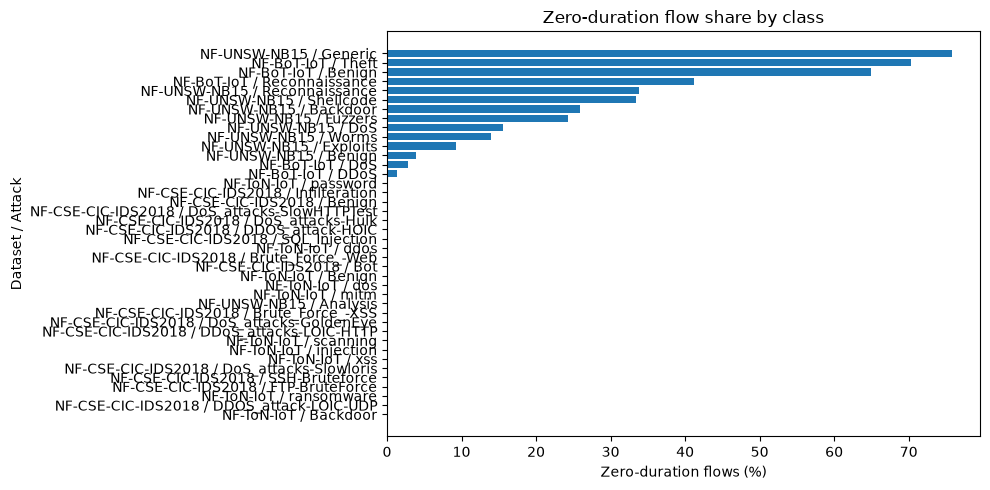

In [13]:
# Measure zero-duration shares by Dataset and class.
extra_zero_by_class = q("""
SELECT Dataset, Attack, Label, count(*) AS rows,
 count(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS = 0) AS zero_duration_rows,
 count(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS = 0) * 100.0 / count(*) AS zero_duration_pct
FROM flows
GROUP BY Dataset, Attack, Label
ORDER BY zero_duration_pct DESC
""")
display(extra_zero_by_class.head(50))  # Show at most 50 rows.
plot_zero = extra_zero_by_class.sort_values("zero_duration_pct").copy()
plot_zero["label"] = plot_zero["Dataset"] + " / " + plot_zero["Attack"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(plot_zero["label"], plot_zero["zero_duration_pct"])
ax.set_title("Zero-duration flow share by class")
ax.set_xlabel("Zero-duration flows (%)")
ax.set_ylabel("Dataset / Attack")
show_plot(fig)

In [14]:
# Compare zero and one durations, including single-packet flows.
extra_duration_granularity = q("""
SELECT Dataset, min(FLOW_DURATION_MILLISECONDS) AS min_duration,
 count(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS = 0) * 100.0 / count(*) AS zero_pct,
 count(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS = 1) * 100.0 / count(*) AS one_pct,
 count(*) FILTER (WHERE IN_PKTS + OUT_PKTS = 1 AND FLOW_DURATION_MILLISECONDS = 0) * 100.0 / NULLIF(count(*) FILTER (WHERE IN_PKTS + OUT_PKTS = 1), 0) AS one_packet_zero_pct,
 count(*) FILTER (WHERE IN_PKTS + OUT_PKTS = 1 AND FLOW_DURATION_MILLISECONDS = 1) * 100.0 / NULLIF(count(*) FILTER (WHERE IN_PKTS + OUT_PKTS = 1), 0) AS one_packet_one_pct
FROM flows
GROUP BY Dataset
ORDER BY Dataset
""")
display(extra_duration_granularity)

,Dataset,min_duration,zero_pct,one_pct,one_packet_zero_pct,one_packet_one_pct
0,NF-BoT-IoT,0,6.213044,0.513883,100.0,0.0
1,NF-CSE-CIC-IDS2018,1,0.000000,37.453039,0.0,100.0
2,NF-ToN-IoT,1,0.000000,68.609871,0.0,100.0
3,NF-UNSW-NB15,0,5.178480,15.132805,100.0,0.0


In [15]:
ratio_sql = """
SELECT Dataset,
 median(SRC_TO_DST_SECOND_BYTES * FLOW_DURATION_MILLISECONDS / NULLIF(OUT_BYTES, 0)) AS src_bytes_out_bytes,
 median(SRC_TO_DST_SECOND_BYTES * FLOW_DURATION_MILLISECONDS / NULLIF(IN_BYTES, 0)) AS src_bytes_in_bytes,
 median(DST_TO_SRC_SECOND_BYTES * FLOW_DURATION_MILLISECONDS / NULLIF(IN_BYTES, 0)) AS dst_bytes_in_bytes,
 median(DST_TO_SRC_SECOND_BYTES * FLOW_DURATION_MILLISECONDS / NULLIF(OUT_BYTES, 0)) AS dst_bytes_out_bytes,
 median(DST_TO_SRC_SECOND_BYTES * 8000 / NULLIF(SRC_TO_DST_AVG_THROUGHPUT, 0)) FILTER (WHERE SRC_TO_DST_AVG_THROUGHPUT > 0) AS dst_src_throughput,
 median(SRC_TO_DST_SECOND_BYTES * 8000 / NULLIF(DST_TO_SRC_AVG_THROUGHPUT, 0)) FILTER (WHERE DST_TO_SRC_AVG_THROUGHPUT > 0) AS src_dst_throughput
FROM flows
WHERE FLOW_DURATION_MILLISECONDS > 0 AND isfinite(SRC_TO_DST_SECOND_BYTES) AND isfinite(DST_TO_SRC_SECOND_BYTES) AND IN_BYTES > 0 AND OUT_BYTES > 0
GROUP BY Dataset ORDER BY Dataset
"""
byte_ratios = q(ratio_sql)
display(byte_ratios)

,Dataset,src_bytes_out_bytes,src_bytes_in_bytes,dst_bytes_in_bytes,dst_bytes_out_bytes,dst_src_throughput,src_dst_throughput
0,NF-BoT-IoT,1.0,0.244444,1.000000,4.090909,1.005586,1.027266
1,NF-CSE-CIC-IDS2018,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
2,NF-ToN-IoT,0.0,0.000000,0.008929,0.016667,0.008929,0.000000
3,NF-UNSW-NB15,1.0,1.407318,1.000000,0.710571,1.027778,1.027778


#### Osservazioni

- Gli unici valori mancanti o non finiti sono in `SRC_TO_DST_SECOND_BYTES` e `DST_TO_SRC_SECOND_BYTES` (`missing`, `quality_detail`): 1.898.421 valori +inf (664.755 + 1.052.105 + 59.068 + 122.493) e 450.775 NULL (387.350 + 63.425), solo in BoT-IoT e UNSW-NB15. Non ci sono NaN né -inf. Le colonne IAT e i due timestamp sono pulite.
- Tutti questi casi stanno su flussi con durata 0; con durata positiva non ce n'è nessuno (`zero_rows`, `zero_status`). I NULL compaiono quando `OUT_BYTES` è 0 (0/0), i +inf quando i byte sono positivi. `DST_TO_SRC_SECOND_BYTES` non ha NULL perché `IN_BYTES` è sempre almeno 1.
- La durata 0 dipende dalla sorgente (`extra_duration_granularity`): in BoT-IoT e UNSW-NB15 il minimo è 0 ms (6,21% e 5,18% delle righe) e tutti i flussi da un pacchetto durano 0 ms. In CSE-CIC-IDS2018 e ToN-IoT il minimo è 1 ms e tutti i flussi da un pacchetto durano 1 ms.
- La quota di durata 0 cambia molto con la classe (`extra_zero_by_class`): in BoT-IoT va dal 70,3% di `Theft` e 64,9% di `Benign` al 2,8% di `DoS` e 1,3% di `DDoS`; in UNSW-NB15 dal 75,8% di `Generic` al 3,9% di `Benign` e a 0% per `Analysis`. In BoT-IoT, 664.755 dei 1.052.105 flussi a durata 0 (63%) hanno byte in entrambe le direzioni, quindi non sono solo flussi da un pacchetto.
- In BoT-IoT e UNSW-NB15 le due colonne SECOND_BYTES coincidono al 100% con byte/durata, ma con le direzioni incrociate: `SRC_TO_DST_SECOND_BYTES` ≈ `OUT_BYTES`/durata e `DST_TO_SRC_SECOND_BYTES` ≈ `IN_BYTES`/durata (byte per millisecondo). In CSE-CIC-IDS2018 e ToN-IoT nessuna combinazione supera il 18% (`extra_rate_checks`): la definizione della colonna cambia da una sorgente all'altra.

#### Note per la pulizia

- Escludere SECOND_BYTES dalle feature: derivano da colonne già presenti, hanno definizioni diverse tra le sorgenti e i valori anomali seguono la durata (e la classe), quindi imputarli aggiungerebbe un'informazione che il modello può sfruttare. Si tengono grezze solo per tracciabilità.
- Non eliminare i flussi a durata 0. Alternative: portare a 1 ms in BoT-IoT e UNSW-NB15 (allinea il caso dei flussi da un pacchetto, non tutto l'arrotondamento) oppure aggiungere `is_zero_duration`. Da confrontare con un'ablation, perché l'indicatore può diventare una scorciatoia (la quota va da 0% a 76% tra le classi).

#### Note per l'addestramento

- `BYTE_RATE_COLS` resta fuori dalle feature. Se servono tassi di trasferimento, si ricostruiscono in modo uniforme da `IN_BYTES`, `OUT_BYTES` e durata, con una regola esplicita per durata 0.
- Provare con un'ablation (anche leave-one-dataset-out) l'effetto di `is_zero_duration`.

In [16]:
# La query misura quanto spesso il rapporto calcolato è entro l'uno per cento da uno.
extra_rate_checks = q("""
SELECT Dataset,
 count(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS > 0 AND isfinite(SRC_TO_DST_SECOND_BYTES) AND OUT_BYTES > 0 AND abs(SRC_TO_DST_SECOND_BYTES * FLOW_DURATION_MILLISECONDS / NULLIF(OUT_BYTES, 0) - 1) < 0.01) * 100.0 / NULLIF(count(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS > 0 AND isfinite(SRC_TO_DST_SECOND_BYTES) AND OUT_BYTES > 0), 0) AS src_out_match_pct,
 count(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS > 0 AND isfinite(SRC_TO_DST_SECOND_BYTES) AND IN_BYTES > 0 AND abs(SRC_TO_DST_SECOND_BYTES * FLOW_DURATION_MILLISECONDS / NULLIF(IN_BYTES, 0) - 1) < 0.01) * 100.0 / NULLIF(count(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS > 0 AND isfinite(SRC_TO_DST_SECOND_BYTES) AND IN_BYTES > 0), 0) AS src_in_match_pct,
 count(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS > 0 AND isfinite(DST_TO_SRC_SECOND_BYTES) AND IN_BYTES > 0 AND abs(DST_TO_SRC_SECOND_BYTES * FLOW_DURATION_MILLISECONDS / NULLIF(IN_BYTES, 0) - 1) < 0.01) * 100.0 / NULLIF(count(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS > 0 AND isfinite(DST_TO_SRC_SECOND_BYTES) AND IN_BYTES > 0), 0) AS dst_in_match_pct,
 count(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS > 0 AND isfinite(DST_TO_SRC_SECOND_BYTES) AND OUT_BYTES > 0 AND abs(DST_TO_SRC_SECOND_BYTES * FLOW_DURATION_MILLISECONDS / NULLIF(OUT_BYTES, 0) - 1) < 0.01) * 100.0 / NULLIF(count(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS > 0 AND isfinite(DST_TO_SRC_SECOND_BYTES) AND OUT_BYTES > 0), 0) AS dst_out_match_pct
FROM flows
GROUP BY Dataset
ORDER BY Dataset
""")
display(extra_rate_checks)

,Dataset,src_out_match_pct,src_in_match_pct,dst_in_match_pct,dst_out_match_pct
0,NF-BoT-IoT,100.000000,0.051625,100.000000,0.196802
1,NF-CSE-CIC-IDS2018,16.922715,0.249956,12.329440,0.099801
2,NF-ToN-IoT,17.519477,1.616420,9.186741,3.303720
3,NF-UNSW-NB15,100.000000,0.016898,100.000000,0.016963


In [17]:
# Summarize each column status by byte presence in both directions.
extra_rate_status_parts = []
for extra_rate_column in BYTE_RATE_COLS:
    extra_rate_name = sql_ident(extra_rate_column)
    extra_rate_status_parts.append(f"""
    SELECT Dataset, '{extra_rate_column}' AS column_name,
      CASE WHEN {extra_rate_name} IS NULL THEN 'NULL'
           WHEN isnan({extra_rate_name}) THEN 'NaN'
           WHEN isinf({extra_rate_name}) THEN 'Inf'
           ELSE 'finite' END AS value_status,
      OUT_BYTES > 0 AS out_bytes_positive, IN_BYTES > 0 AS in_bytes_positive,
      count(*) AS rows
    FROM flows
    GROUP BY Dataset, value_status, out_bytes_positive, in_bytes_positive
    """)
extra_rate_status = q(" UNION ALL ".join(extra_rate_status_parts) + " ORDER BY Dataset, column_name, value_status")
display(extra_rate_status.head(50))  # Show at most 50 groups.

,Dataset,column_name,value_status,out_bytes_positive,in_bytes_positive,rows
0,NF-BoT-IoT,DST_TO_SRC_SECOND_BYTES,Inf,False,True,387350
1,NF-BoT-IoT,DST_TO_SRC_SECOND_BYTES,Inf,True,True,664755
2,NF-BoT-IoT,DST_TO_SRC_SECOND_BYTES,finite,True,True,4166106
3,NF-BoT-IoT,DST_TO_SRC_SECOND_BYTES,finite,False,True,11715597
4,NF-BoT-IoT,SRC_TO_DST_SECOND_BYTES,Inf,True,True,664755
5,NF-BoT-IoT,SRC_TO_DST_SECOND_BYTES,NULL,False,True,387350
6,NF-BoT-IoT,SRC_TO_DST_SECOND_BYTES,finite,True,True,4166106
7,NF-BoT-IoT,SRC_TO_DST_SECOND_BYTES,finite,False,True,11715597
8,NF-CSE-CIC-IDS2018,DST_TO_SRC_SECOND_BYTES,finite,True,True,18140162
9,NF-CSE-CIC-IDS2018,DST_TO_SRC_SECOND_BYTES,finite,False,True,1975367


In [18]:
feature_columns = [c for c in ALL_COLUMNS if c not in {"row_id", "Dataset"}]
feature_sql = ", ".join(sql_ident(c) for c in feature_columns)
# Exact duplicate grouping is a full-table operation; row_id is excluded because it is unique by design.
exact_duplicate_groups = q(f"SELECT Dataset, COUNT(*) AS groups, SUM(n - 1) AS duplicated_rows FROM (SELECT Dataset, {feature_sql}, COUNT(*) AS n FROM flows GROUP BY Dataset, {feature_sql} HAVING COUNT(*) > 1) GROUP BY Dataset")
exact_duplicate_rows = int(exact_duplicate_groups["duplicated_rows"].sum()) if len(exact_duplicate_groups) else 0
exact_duplicate_pct = 100.0 * exact_duplicate_rows / total_rows if total_rows else 0.0
display(exact_duplicate_groups)
print(f"Duplicated rows: {exact_duplicate_rows:,} ({exact_duplicate_pct:.4f}%)")
features_without_time = [c for c in feature_columns if c not in TIME_COLS]
without_time_sql = ", ".join(sql_ident(c) for c in features_without_time)
exact_duplicates_without_time = q(f"SELECT Dataset, SUM(n - 1) AS duplicated_rows FROM (SELECT Dataset, {without_time_sql}, COUNT(*) AS n FROM flows GROUP BY Dataset, {without_time_sql} HAVING COUNT(*) > 1) GROUP BY Dataset")
display(exact_duplicates_without_time)

,Dataset,groups,duplicated_rows
0,NF-UNSW-NB15,14815,14815.0
1,NF-CSE-CIC-IDS2018,628200,628474.0
2,NF-ToN-IoT,480040,1816137.0


Duplicated rows: 2,459,426 (3.6743%)


,Dataset,duplicated_rows
0,NF-UNSW-NB15,24417.0
1,NF-BoT-IoT,5151.0
2,NF-CSE-CIC-IDS2018,1169944.0
3,NF-ToN-IoT,8907276.0


In [19]:
conflict_key = [c for c in ALL_COLUMNS if c not in {"row_id", "Dataset", "Label", "Attack", *TIME_COLS}]
conflict_sql = ", ".join(sql_ident(c) for c in conflict_key)
# This full-table grouping excludes row_id and labels to find identical features with conflicting targets.
conflicting_label_groups = q(f"SELECT COUNT(*) AS conflicting_label_groups FROM (SELECT Dataset, {conflict_sql} FROM flows GROUP BY Dataset, {conflict_sql} HAVING COUNT(DISTINCT Label) > 1 OR COUNT(DISTINCT Attack) > 1)").iloc[0]["conflicting_label_groups"]
conflicting_label_groups = int(conflicting_label_groups)
print(f"Conflicting-label groups: {conflicting_label_groups:,}")

Conflicting-label groups: 16,511


In [20]:
conflict_diagnostic_key = [c for c in ALL_COLUMNS if c not in {"row_id", "Dataset", "Label", "Attack", *TIME_COLS}]
conflict_diagnostic_sql = ", ".join(sql_ident(c) for c in conflict_diagnostic_key)
conflict_group_summary = q(f"SELECT Dataset, CASE WHEN label_count > 1 THEN 'Benign vs Attack' ELSE 'Attack differs' END AS conflict_type, COUNT(*) AS groups, SUM(group_rows) AS rows_involved, MAX(group_rows) AS largest_group FROM (SELECT Dataset, {conflict_diagnostic_sql}, COUNT(*) AS group_rows, COUNT(DISTINCT Label) AS label_count, COUNT(DISTINCT Attack) AS attack_count FROM flows GROUP BY Dataset, {conflict_diagnostic_sql} HAVING COUNT(DISTINCT Label) > 1 OR COUNT(DISTINCT Attack) > 1) GROUP BY Dataset, conflict_type ORDER BY Dataset, conflict_type")
display(conflict_group_summary)

,Dataset,conflict_type,groups,rows_involved,largest_group
0,NF-BoT-IoT,Attack differs,15432,31526.0,3
1,NF-CSE-CIC-IDS2018,Attack differs,47,96.0,4
2,NF-CSE-CIC-IDS2018,Benign vs Attack,152,10997.0,1078
3,NF-ToN-IoT,Attack differs,742,7813.0,29
4,NF-ToN-IoT,Benign vs Attack,56,469.0,26
5,NF-UNSW-NB15,Attack differs,82,173.0,4


In [21]:
conflict_label_pairs = q(f"SELECT Dataset, label_set, attack_set, COUNT(*) AS groups FROM (SELECT Dataset, {conflict_diagnostic_sql}, string_agg(DISTINCT CAST(Label AS VARCHAR), ' | ') AS label_set, string_agg(DISTINCT CAST(Attack AS VARCHAR), ' | ') AS attack_set, COUNT(DISTINCT Label) AS label_count, COUNT(DISTINCT Attack) AS attack_count FROM flows GROUP BY Dataset, {conflict_diagnostic_sql} HAVING COUNT(DISTINCT Label) > 1 OR COUNT(DISTINCT Attack) > 1) GROUP BY Dataset, label_set, attack_set ORDER BY groups DESC LIMIT 50")
display(conflict_label_pairs)

,Dataset,label_set,attack_set,groups
0,NF-BoT-IoT,1,DDoS | DoS,7784
1,NF-BoT-IoT,1,DoS | DDoS,7648
2,NF-ToN-IoT,1,injection | ddos,370
3,NF-ToN-IoT,1,ddos | injection,363
4,NF-CSE-CIC-IDS2018,0 | 1,Benign | Infilteration,40
5,NF-CSE-CIC-IDS2018,1 | 0,Benign | Infilteration,24
6,NF-CSE-CIC-IDS2018,1 | 0,Infilteration | Benign,23
7,NF-CSE-CIC-IDS2018,1,Brute_Force_-XSS | SQL_Injection,23
8,NF-CSE-CIC-IDS2018,1,SQL_Injection | Brute_Force_-XSS,20
9,NF-CSE-CIC-IDS2018,0 | 1,Infilteration | Benign,16


In [22]:
conflict_duplicate_overlap = q(f"SELECT Dataset, COUNT(*) AS conflicting_groups, SUM(group_rows) AS conflicting_rows, SUM(duplicate_rows) AS repeated_rows_within_target_variants FROM (SELECT Dataset, {conflict_diagnostic_sql}, SUM(target_rows) AS group_rows, SUM(target_rows - 1) AS duplicate_rows, COUNT(DISTINCT Label) AS label_count, COUNT(DISTINCT Attack) AS attack_count FROM (SELECT Dataset, {conflict_diagnostic_sql}, Label, Attack, COUNT(*) AS target_rows FROM flows GROUP BY Dataset, {conflict_diagnostic_sql}, Label, Attack) GROUP BY Dataset, {conflict_diagnostic_sql} HAVING COUNT(DISTINCT Label) > 1 OR COUNT(DISTINCT Attack) > 1) GROUP BY Dataset ORDER BY Dataset")
display(conflict_duplicate_overlap)
conflict_split_risk = q(f"SELECT Dataset, COUNT(*) AS conflicting_groups, SUM(1 - POWER(0.75, group_rows) - POWER(0.25, group_rows)) AS expected_groups_crossing_random_75_25_split, SUM(group_rows * (0.75 * (1 - POWER(0.75, group_rows - 1)) + 0.25 * (1 - POWER(0.25, group_rows - 1)))) AS expected_rows_with_same_feature_group_across_splits FROM (SELECT Dataset, {conflict_diagnostic_sql}, COUNT(*) AS group_rows, COUNT(DISTINCT Label) AS label_count, COUNT(DISTINCT Attack) AS attack_count FROM flows GROUP BY Dataset, {conflict_diagnostic_sql} HAVING COUNT(DISTINCT Label) > 1 OR COUNT(DISTINCT Attack) > 1) GROUP BY Dataset ORDER BY Dataset")
display(conflict_split_risk)
# These are analytical expectations under independent 75/25 row assignment, not a simulated split.

,Dataset,conflicting_groups,conflicting_rows,repeated_rows_within_target_variants
0,NF-BoT-IoT,15432,31526.0,662.0
1,NF-CSE-CIC-IDS2018,199,11093.0,10655.0
2,NF-ToN-IoT,798,8282.0,6683.0
3,NF-UNSW-NB15,82,173.0,6.0


,Dataset,conflicting_groups,expected_groups_crossing_random_75_25_split,expected_rows_with_same_feature_group_across_splits
0,NF-BoT-IoT,15432,5911.125000,12194.625000
1,NF-CSE-CIC-IDS2018,199,146.661940,10947.567661
2,NF-ToN-IoT,798,571.461476,7721.952684
3,NF-UNSW-NB15,82,32.367188,70.031250


In [23]:
domains = {"L4_SRC_PORT": (0, 65535), "L4_DST_PORT": (0, 65535), "PROTOCOL": (0, 255), "TCP_FLAGS": (0, 255), "CLIENT_TCP_FLAGS": (0, 255), "SERVER_TCP_FLAGS": (0, 255), "MIN_TTL": (0, 255), "MAX_TTL": (0, 255)}
for c in [*IAT_COLS, "SRC_TO_DST_AVG_THROUGHPUT", "DST_TO_SRC_AVG_THROUGHPUT", "DNS_TTL_ANSWER", *TIME_COLS, "IN_BYTES", "IN_PKTS", "OUT_BYTES", "OUT_PKTS", "FLOW_DURATION_MILLISECONDS", "DURATION_IN", "DURATION_OUT", "LONGEST_FLOW_PKT", "SHORTEST_FLOW_PKT", "MIN_IP_PKT_LEN", "MAX_IP_PKT_LEN", "SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES", "RETRANSMITTED_IN_BYTES", "RETRANSMITTED_IN_PKTS", "RETRANSMITTED_OUT_BYTES", "RETRANSMITTED_OUT_PKTS", "L7_PROTO"]:
    domains[c] = (0, None)
domain_checks = []
for c, (lower, upper) in domains.items():
    if c not in ALL_COLUMNS:
        continue
    x = sql_ident(c)
    conditions = [f"{x} <= 0" if c in TIME_COLS else f"{x} < {lower}"]
    if upper is not None:
        conditions.append(f"{x} > {upper}")
    domain_checks.append(f"COUNT(*) FILTER (WHERE {' OR '.join(conditions)}) AS {sql_ident(c)}")
out_domain_sql = ", ".join(domain_checks) if domain_checks else "0 AS no_domain_checks"
out_domain_values = q(f"SELECT {out_domain_sql} FROM flows").iloc[0]
out_of_domain_count = int(out_domain_values.sum())
out_of_domain_table = pd.DataFrame({"feature": list(out_domain_values.index), "violations": list(out_domain_values.values)})
display(out_of_domain_table[out_of_domain_table["violations"] > 0])
print(f"Out-of-domain values: {out_of_domain_count:,}")

,feature,violations


Out-of-domain values: 0


In [24]:
rules = [("MIN_TTL", "MAX_TTL"), ("SHORTEST_FLOW_PKT", "LONGEST_FLOW_PKT"), ("MIN_IP_PKT_LEN", "MAX_IP_PKT_LEN")]
violation_conditions = []
for a, b in rules:
    if {a, b}.issubset(ALL_COLUMNS):
        violation_conditions.append((f"{a} <= {b}", f"{sql_ident(a)} > {sql_ident(b)}"))
if {"DURATION_IN", "FLOW_DURATION_MILLISECONDS"}.issubset(ALL_COLUMNS):
    violation_conditions.append(("DURATION_IN <= FLOW_DURATION_MILLISECONDS", "DURATION_IN > FLOW_DURATION_MILLISECONDS"))
if {"DURATION_OUT", "FLOW_DURATION_MILLISECONDS"}.issubset(ALL_COLUMNS):
    violation_conditions.append(("DURATION_OUT <= FLOW_DURATION_MILLISECONDS", "DURATION_OUT > FLOW_DURATION_MILLISECONDS"))
for packets, byte_count in [("IN_PKTS", "IN_BYTES"), ("OUT_PKTS", "OUT_BYTES")]:
    if {packets, byte_count}.issubset(ALL_COLUMNS):
        violation_conditions.append((f"{packets} = 0 implies {byte_count} = 0", f"{sql_ident(packets)} = 0 AND {sql_ident(byte_count)} <> 0"))
for retransmitted, total in [("RETRANSMITTED_IN_BYTES", "IN_BYTES"), ("RETRANSMITTED_OUT_BYTES", "OUT_BYTES")]:
    if {retransmitted, total}.issubset(ALL_COLUMNS):
        violation_conditions.append((f"{retransmitted} <= {total}", f"{sql_ident(retransmitted)} > {sql_ident(total)}"))
for prefix in ["SRC_TO_DST", "DST_TO_SRC"]:
    minimum, average, maximum, stddev = (f"{prefix}_IAT_{suffix}" for suffix in ["MIN", "AVG", "MAX", "STDDEV"])
    violation_conditions.extend([
        (f"{minimum} <= {average} <= {maximum}", f"{sql_ident(minimum)} > {sql_ident(average)} OR {sql_ident(average)} > {sql_ident(maximum)}"),
        (f"{minimum} <= {maximum}", f"{sql_ident(minimum)} > {sql_ident(maximum)}"),
        (f"{stddev} >= 0", f"{sql_ident(stddev)} < 0"),
    ])
consistency_parts = [f"COUNT(*) FILTER (WHERE {condition}) AS {sql_ident(name)}" for name, condition in violation_conditions]
consistency_sql = ", ".join(consistency_parts) if consistency_parts else "0 AS no_consistency_checks"
consistency_values = q(f"SELECT {consistency_sql} FROM flows").iloc[0]
consistency_violations = int(consistency_values.sum())
display(pd.DataFrame({"rule": consistency_values.index, "violations": consistency_values.values}))


,rule,violations
0,MIN_TTL <= MAX_TTL,0
1,SHORTEST_FLOW_PKT <= LONGEST_FLOW_PKT,0
2,MIN_IP_PKT_LEN <= MAX_IP_PKT_LEN,0
3,DURATION_IN <= FLOW_DURATION_MILLISECONDS,11277
4,DURATION_OUT <= FLOW_DURATION_MILLISECONDS,0
5,IN_PKTS = 0 implies IN_BYTES = 0,0
6,OUT_PKTS = 0 implies OUT_BYTES = 0,0
7,RETRANSMITTED_IN_BYTES <= IN_BYTES,0
8,RETRANSMITTED_OUT_BYTES <= OUT_BYTES,0
9,SRC_TO_DST_IAT_MIN <= SRC_TO_DST_IAT_AVG <= SR...,1002492


#### Osservazioni

- Duplicati esatti (tutte le colonne tranne `row_id`, timestamp compresi): 2.459.426 righe, 3,67% del totale (`exact_duplicate_groups`). ToN-IoT 1.816.137 (6,6%), CSE-CIC-IDS2018 628.474 (3,1%), UNSW-NB15 14.815 (0,6%), BoT-IoT nessuno.
- Se si ignorano anche i timestamp, i duplicati salgono a 10.106.788 (15,1%, `exact_duplicates_without_time`): ToN-IoT 8.907.276 (32,4%), CSE-CIC-IDS2018 1.169.944 (5,8%), UNSW-NB15 24.417 (1,0%), BoT-IoT 5.151 (0,03%). La differenza sono flussi con feature identiche ma in istanti diversi. `[ipotesi]` traffico ripetitivo, non copie vere.
- Conflitti (feature uguali, timestamp esclusi, etichette diverse): 16.511 gruppi per 51.074 righe, lo 0,08% del totale. Quasi tutti cambiano solo il tipo di attacco, con `Label` uguale (16.303 gruppi su 16.511). In BoT-IoT sono 15.432 gruppi (31.526 righe), tutti `DoS` contro `DDoS`: circa lo 0,2% delle 15.185.072 righe `DoS` e `DDoS`. In ToN-IoT i più numerosi sono `injection` contro `ddos` (oltre 700 gruppi).
- I conflitti tra Benign e Attack sono solo 208 gruppi, 11.466 righe (circa 0,017%): CSE-CIC-IDS2018 152 gruppi con 10.997 righe (il gruppo più grande ha 1.078 righe) e ToN-IoT 56 gruppi con 469 righe (`conflict_group_summary`). Tra le coppie più frequenti di CSE-CIC-IDS2018 c'è `Benign` contro `Infilteration`.
- Con uno split casuale 75/25 ci si aspetta che circa 30.900 righe in conflitto abbiano una riga gemella nell'altro lato (`conflict_split_risk`). È lo 0,05% del dataset, ma circa il 60% delle righe in conflitto; in CSE-CIC-IDS2018 e ToN-IoT supera il 90% (10.948 su 11.093 e 7.722 su 8.282).
- Domini: nessuna violazione (porte 0–65535, `PROTOCOL`, flag e TTL in 0–255, valori non negativi, timestamp positivi).
- Regole di coerenza: 0 violazioni su TTL, lunghezze dei pacchetti, `DURATION_OUT`, pacchetti/byte, ritrasmissioni, `IAT_MIN <= IAT_MAX` e `IAT_STDDEV >= 0`. Violazioni: `DURATION_IN > FLOW_DURATION_MILLISECONDS` in 11.277 righe (0,017%) e `IAT_MIN <= IAT_AVG <= IAT_MAX` in 1.002.492 righe SRC→DST (1,50%) e 623.354 righe DST→SRC (0,93%). Il notebook non dice se il problema sia `AVG < MIN` o `AVG > MAX`, né in quali sorgenti.

#### Note per la pulizia

- Duplicati con timestamp (2,46 milioni): sono i candidati da eliminare prima di costruire sequenze o finestre. Quelli senza timestamp (10,1 milioni) non vanno eliminati: sono eventi in istanti diversi, soprattutto in ToN-IoT.
- Conflitti: non eliminarli in blocco, marcarli con `is_conflict` (51.074 righe). Per una versione tabellare pulita si possono togliere solo i 208 gruppi Benign contro Attack (11.466 righe). I conflitti `DoS`/`DDoS` di BoT-IoT riguardano pochi flussi (0,2%): non bastano per dire che le due classi siano indistinguibili (vedi capitolo 4).
- `DURATION_IN > FLOW_DURATION_MILLISECONDS` e incoerenze IAT: non correggere, aggiungere un flag (per esempio `iat_inconsistent`) e tenere le righe.

#### Note per l'addestramento

- Fare dedup prima dello split, oppure uno split a gruppi (stessa firma di feature dallo stesso lato): altrimenti le metriche sono troppo ottimistiche, soprattutto su ToN-IoT.
- Per le sequenze, togliere le righe prima di costruire le finestre, non dopo: si spezzerebbe la continuità temporale.
- Le incoerenze IAT (1,5% e 0,9%) non bloccano; con un'ablation si verifica se il flag aiuta o fa da scorciatoia.

## 4. Class distribution

In [25]:
label_counts = q("SELECT Label, COUNT(*) AS rows, 100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS percentage FROM flows GROUP BY Label ORDER BY rows DESC")
attack_counts = q("SELECT Attack, COUNT(*) AS rows, 100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS percentage FROM flows GROUP BY Attack ORDER BY rows DESC")
display(label_counts)
display(attack_counts)

,Label,rows,percentage
0,0,36596560,54.674757
1,1,30338461,45.325243


,Attack,rows,percentage
0,Benign,36596560,54.674757
1,DoS,8040170,12.011903
2,DDoS,7150882,10.683319
3,ddos,4141256,6.186979
4,xss,2834435,4.234607
5,Reconnaissance,1712206,2.558012
6,password,1594777,2.382575
7,scanning,1358977,2.030293
8,DDOS_attack-HOIC,1032311,1.542258
9,FTP-BruteForce,386720,0.577754


Majority-to-minority class ratio: 1.21


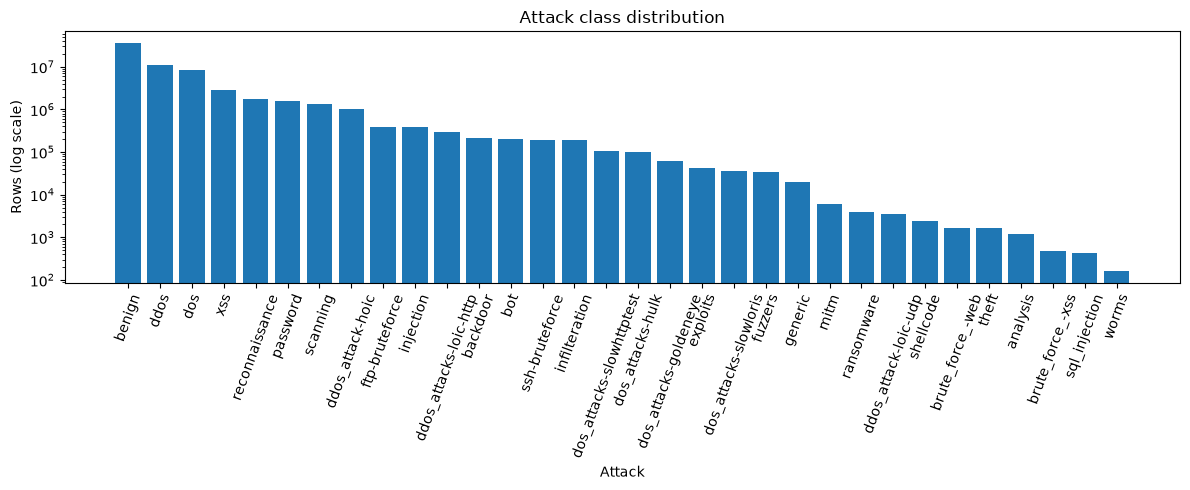

In [26]:
label_sizes = label_counts["rows"]
imbalance_ratio = float(label_sizes.max() / label_sizes.min()) if len(label_sizes) and label_sizes.min() else np.nan
print(f"Majority-to-minority class ratio: {imbalance_ratio:.2f}")

attack_counts_plot = (
    attack_counts
    .assign(
        Attack_norm=attack_counts["Attack"]
        .astype(str)
        .str.strip()
        .str.casefold()
    )
    .groupby("Attack_norm", as_index=False)["rows"]
    .sum()
    .sort_values("rows", ascending=False, kind="stable")
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(attack_counts_plot["Attack_norm"], attack_counts_plot["rows"])
ax.set_yscale("log")
ax.set_title("Attack class distribution")
ax.set_xlabel("Attack")
ax.set_ylabel("Rows (log scale)")
ax.tick_params(axis="x", rotation=70)
show_plot(fig)

In [27]:
dataset_labels = q("SELECT Dataset, Label, COUNT(*) AS rows FROM flows GROUP BY Dataset, Label ORDER BY Dataset, Label")
dataset_label_pct = dataset_labels.pivot(index="Dataset", columns="Label", values="rows").fillna(0)
for label in dataset_label_pct.columns:
    dataset_label_pct[f"Label {label} percentage"] = 100 * dataset_label_pct[label] / dataset_label_pct.sum(axis=1)
display(dataset_labels)
display(dataset_label_pct.reset_index())

,Dataset,Label,rows
0,NF-BoT-IoT,0,51989
1,NF-BoT-IoT,1,16881819
2,NF-CSE-CIC-IDS2018,0,17514626
3,NF-CSE-CIC-IDS2018,1,2600903
4,NF-ToN-IoT,0,16792214
5,NF-ToN-IoT,1,10728046
6,NF-UNSW-NB15,0,2237731
7,NF-UNSW-NB15,1,127693


Label,Dataset,0,1,Label 0 percentage,Label 1 percentage
0,NF-BoT-IoT,51989,16881819,0.307013,99.692985
1,NF-CSE-CIC-IDS2018,17514626,2600903,87.070173,12.929771
2,NF-ToN-IoT,16792214,10728046,61.017643,38.982271
3,NF-UNSW-NB15,2237731,127693,94.601687,5.398097


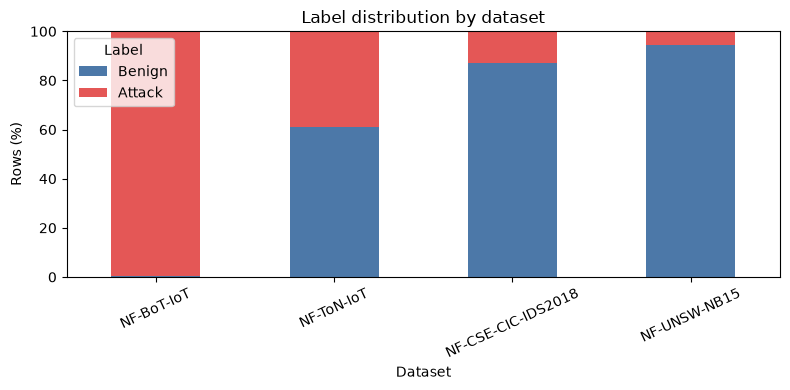

In [28]:
label_values = sorted(dataset_labels["Label"].dropna().unique())
percentage_columns = [f"Label {label} percentage" for label in label_values]

label_plot = dataset_label_pct[percentage_columns].copy()
label_plot = label_plot.loc[dataset_label_pct["Label 1 percentage"].sort_values(ascending=False, kind="stable").index]
label_plot.columns = [
    "Benign" if label == 0 else "Attack" if label == 1 else f"Label {label}"
    for label in label_values
]

label_colors = [
    "#4C78A8" if label == 0 else "#E45756" if label == 1 else "#72B7B2"
    for label in label_values
]

fig, ax = plt.subplots(figsize=(8, 4))
label_plot.plot(kind="bar", stacked=True, color=label_colors, ax=ax)
ax.set_title("Label distribution by dataset")
ax.set_xlabel("Dataset")
ax.set_ylabel("Rows (%)")
ax.set_ylim(0, 100)
ax.legend(title="Label")
ax.tick_params(axis="x", rotation=25)
show_plot(fig)

#### Osservazioni

- In totale ci sono 36.596.560 flussi Benign (54,67%) e 30.338.461 Attack (45,33%), rapporto 1,21. È un dato fuorviante, perché il bilanciamento cambia molto da sorgente a sorgente (`dataset_label_pct`): BoT-IoT è attacco al 99,69% (solo 51.989 flussi Benign), CSE-CIC-IDS2018 è Benign all'87,07%, ToN-IoT al 61,02%, UNSW-NB15 al 94,60% (attacchi 5,40%).
- `Attack` ha 34 valori (Benign più 33 attacchi) e sono molto sbilanciati: da `DoS` 8.040.170, `DDoS` 7.150.882, `ddos` 4.141.256 e `xss` 2.834.435 fino a `Worms` 158, `SQL_Injection` 440, `Brute_Force_-XSS` 480, `Analysis` 1.226, `Theft` 1.615 e `Brute_Force_-Web` 1.618. Tra la classe di attacco più grande e la più piccola il rapporto supera 50.000 a 1.
- I nomi non sono uniformi: `DoS` (BoT-IoT) e `dos` (ToN-IoT), `DDoS` e `ddos`, e in CSE-CIC-IDS2018 `DDOS_attack-*` contro `DDoS_attacks-*`. `Infilteration` ha un refuso nel nome. Non è documentato se classi con nomi diversi (per esempio `Reconnaissance` e `scanning`) siano equivalenti.
- La maggior parte delle classi di attacco compare in una sola sorgente. Solo tre nomi sono condivisi: `DoS` e `Reconnaissance` (BoT-IoT e UNSW-NB15) e `Backdoor` (ToN-IoT e UNSW-NB15). Nei conteggi di `Attack` questi nomi sommano righe di sorgenti diverse (per esempio `DoS` 8.040.170 = 8.034.190 + 5.980), ma non è detto che indichino lo stesso comportamento.

#### Note per la pulizia

- Non unire i nomi alla cieca: serve una mappa esplicita (`Dataset`, `Attack`) → famiglia (colonna `attack_family`), tenendo anche `Attack` originale. Il minimo è uniformare maiuscole e minuscole, ma attenzione: `casefold` unisce anche `DoS` e `dos`, `DDoS` e `ddos` di sorgenti diverse, quindi è già una scelta di significato.
- Il conflitto `DoS`/`DDoS` in BoT-IoT riguarda solo lo 0,2% delle righe (capitolo 3): non basta per accorparle. Meglio guardare la matrice di confusione del primo modello e accorpare solo se le due classi si confondono molto.

#### Note per l'addestramento

- Riportare macro-F1 e metriche per classe e per `Dataset`: l'accuracy globale è dominata da `DoS`/`DDoS` di BoT-IoT e dal Benign di CSE-CIC-IDS2018 e ToN-IoT.
- Usare pesi di classe, non oversampling massiccio su 67 milioni di righe. Le classi sotto circa 2.000 righe (`Worms`, `SQL_Injection`, `Brute_Force_-XSS`, `Analysis`, `Theft`, `Brute_Force_-Web`) vanno raggruppate, escluse dal multiclasse o valutate solo nel binario.
- BoT-IoT è quasi solo attacco: se il modello vede `Dataset`, o feature che lo identificano, può imparare "BoT = attacco". Non usare `Dataset` come feature e controllare con leave-one-dataset-out.

## 5. Feature distributions

In [29]:
GROUPS = {
    "identifiers and metadata": ["row_id", "Dataset"],
    "IP addresses and ports": ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "L4_SRC_PORT", "L4_DST_PORT"],
    "protocols and flags": ["PROTOCOL", "L7_PROTO", "TCP_FLAGS", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS", "ICMP_TYPE", "ICMP_IPV4_TYPE", "DNS_QUERY_ID", "DNS_QUERY_TYPE", "FTP_COMMAND_RET_CODE"],
    "bytes and packets": ["IN_BYTES", "IN_PKTS", "OUT_BYTES", "OUT_PKTS", "NUM_PKTS_UP_TO_128_BYTES", "NUM_PKTS_128_TO_256_BYTES", "NUM_PKTS_256_TO_512_BYTES", "NUM_PKTS_512_TO_1024_BYTES", "NUM_PKTS_1024_TO_1514_BYTES"],
    "durations": ["FLOW_DURATION_MILLISECONDS", "DURATION_IN", "DURATION_OUT"],
    "TTL and packet sizes": ["MIN_TTL", "MAX_TTL", "LONGEST_FLOW_PKT", "SHORTEST_FLOW_PKT", "MIN_IP_PKT_LEN", "MAX_IP_PKT_LEN"],
    "throughput": ["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES", "SRC_TO_DST_AVG_THROUGHPUT", "DST_TO_SRC_AVG_THROUGHPUT"],
    "retransmissions": ["RETRANSMITTED_IN_BYTES", "RETRANSMITTED_IN_PKTS", "RETRANSMITTED_OUT_BYTES", "RETRANSMITTED_OUT_PKTS"],
    "TCP windows and DNS": ["TCP_WIN_MAX_IN", "TCP_WIN_MAX_OUT", "DNS_TTL_ANSWER"],
    "targets": ["Label", "Attack"],
    "timestamps": TIME_COLS,
    "inter-arrival times": IAT_COLS,
}
assigned = {c: group for group, cols in GROUPS.items() for c in cols}
unclassified_columns = [c for c in ALL_COLUMNS if c not in assigned]
print("Unclassified columns:", unclassified_columns)
display(pd.DataFrame([{"column": c, "group": assigned.get(c, "unclassified")} for c in ALL_COLUMNS]))

Unclassified columns: []


,column,group
0,row_id,identifiers and metadata
1,Dataset,identifiers and metadata
2,FLOW_START_MILLISECONDS,timestamps
3,FLOW_END_MILLISECONDS,timestamps
4,IPV4_SRC_ADDR,IP addresses and ports
5,L4_SRC_PORT,IP addresses and ports
6,IPV4_DST_ADDR,IP addresses and ports
7,L4_DST_PORT,IP addresses and ports
8,PROTOCOL,protocols and flags
9,L7_PROTO,protocols and flags


In [30]:
discrete_columns = {"row_id", "Label", "PROTOCOL", "L7_PROTO", "TCP_FLAGS", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS", "ICMP_TYPE", "ICMP_IPV4_TYPE", "DNS_QUERY_ID", "DNS_QUERY_TYPE", "FTP_COMMAND_RET_CODE", "L4_SRC_PORT", "L4_DST_PORT"}
numeric_columns = schema.loc[schema["column_type"].str.upper().str.contains("INT|DOUBLE|FLOAT|REAL"), "column_name"].tolist()
continuous = [c for c in numeric_columns if c not in discrete_columns and c not in TIME_COLS]
print(f"Continuous features: {len(continuous)}")

Continuous features: 37


#### Zeri, costanti e valori sentinella

Non avere NULL non significa non avere valori mancanti: un mancante può essere scritto come 0. Le analisi seguenti guardano la quota di zeri per feature, fonte, classe e protocollo. Le soglie nel codice sono criteri esplorativi.

Dataset,NF-BoT-IoT,NF-CSE-CIC-IDS2018,NF-ToN-IoT,NF-UNSW-NB15
feature,,,,
FTP_COMMAND_RET_CODE,100.0%,100.0%,99.7%,81.4%
DST_TO_SRC_IAT_MIN,92.3%,75.3%,95.9%,100.0%
DNS_TTL_ANSWER,100.0%,63.9%,95.9%,84.5%
DNS_QUERY_ID,100.0%,63.1%,84.6%,83.9%
DNS_QUERY_TYPE,100.0%,63.1%,84.6%,83.9%
RETRANSMITTED_IN_BYTES,99.9%,92.3%,98.4%,25.7%
RETRANSMITTED_IN_PKTS,99.9%,92.3%,98.4%,25.7%
SRC_TO_DST_IAT_MIN,12.3%,74.6%,90.9%,99.9%
RETRANSMITTED_OUT_BYTES,99.9%,96.9%,99.0%,29.3%


,feature,Dataset,rows,min,max,zero_rate,constant,all_zero
0,FTP_COMMAND_RET_CODE,NF-CSE-CIC-IDS2018,20115529,0.0,0.0,1.0,True,True


,feature,Dataset,zero_rate_0,rows_0,zero_rate_1,rows_1,gap
0,SRC_TO_DST_IAT_MIN,NF-BoT-IoT,77.7,51989.0,12.0,16881819.0,65.6
1,MAX_TTL,NF-ToN-IoT,91.6,16792214.0,29.0,10728046.0,62.6
2,MIN_TTL,NF-ToN-IoT,91.6,16792214.0,29.0,10728046.0,62.6
3,SRC_TO_DST_IAT_STDDEV,NF-BoT-IoT,77.4,51989.0,15.9,16881819.0,61.6
4,SRC_TO_DST_IAT_MAX,NF-BoT-IoT,71.2,51989.0,11.9,16881819.0,59.3
5,DURATION_IN,NF-BoT-IoT,71.1,51989.0,11.9,16881819.0,59.3
6,SRC_TO_DST_IAT_AVG,NF-BoT-IoT,71.2,51989.0,11.9,16881819.0,59.3
7,FLOW_DURATION_MILLISECONDS,NF-BoT-IoT,64.9,51989.0,6.0,16881819.0,58.9
8,MIN_TTL,NF-BoT-IoT,68.5,51989.0,11.4,16881819.0,57.0
9,MAX_TTL,NF-BoT-IoT,68.5,51989.0,11.4,16881819.0,57.0


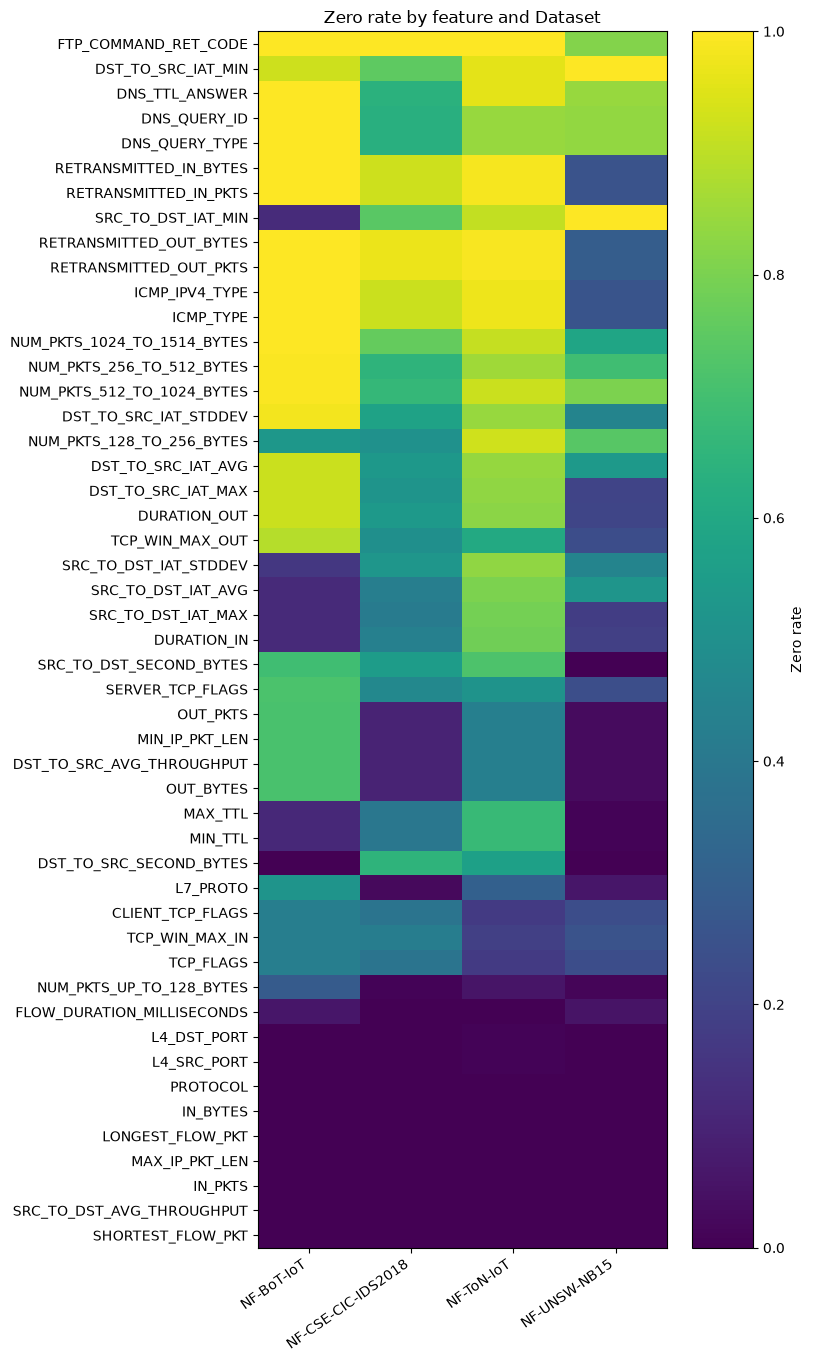

In [31]:
ZERO_RATE_SPARSE = 0.95
ZERO_RATE_GAP = 0.20

zero_columns = [c for c in numeric_columns if c not in {"row_id", "Label", "Attack", "Dataset", *TIME_COLS}]
zero_aggregates = ["COUNT(*) AS rows"]
for column in zero_columns:
    name = sql_ident(column)
    zero_aggregates.extend([
        f"COUNT(*) FILTER (WHERE {name} = 0) AS {sql_ident(column + '__zeros')}",
        f"MIN({name}) AS {sql_ident(column + '__min')}",
        f"MAX({name}) AS {sql_ident(column + '__max')}",
    ])
zero_wide = q("SELECT Dataset, Label, " + ", ".join(zero_aggregates) + " FROM flows GROUP BY Dataset, Label")
zero_records = []
for row in zero_wide.itertuples(index=False, name=None):
    dataset, label, rows, *values = row
    for j, feature in enumerate(zero_columns):
        zeros, minimum, maximum = values[j * 3:j * 3 + 3]
        zero_records.append({"Dataset": dataset, "Label": label, "feature": feature,
                             "rows": int(rows), "zeros": int(zeros), "zero_rate": zeros / rows if rows else float("nan"),
                             "min": minimum, "max": maximum})
zero_by_label = pd.DataFrame(zero_records)
zero_by_dataset = (zero_by_label.groupby(["Dataset", "feature"], as_index=False)
                   .agg(rows=("rows", "sum"), zeros=("zeros", "sum"), min=("min", "min"), max=("max", "max")))
zero_by_dataset["zero_rate"] = zero_by_dataset["zeros"] / zero_by_dataset["rows"]
zero_by_dataset["constant"] = zero_by_dataset["min"] == zero_by_dataset["max"]
zero_by_dataset["all_zero"] = zero_by_dataset["zero_rate"] == 1
zero_pivot = zero_by_dataset.pivot(index="feature", columns="Dataset", values="zero_rate")
zero_pivot["max_zero_rate"] = zero_pivot.max(axis=1)
zero_pivot = zero_pivot.sort_values("max_zero_rate", ascending=False).drop(columns="max_zero_rate")
display(zero_pivot.map(lambda value: f"{value:.1%}"))

display(zero_by_dataset.loc[zero_by_dataset["constant"] | zero_by_dataset["all_zero"],
                            ["feature", "Dataset", "rows", "min", "max", "zero_rate", "constant", "all_zero"]]
        .sort_values(["Dataset", "feature"]).reset_index(drop=True))

label_rates = zero_by_label.pivot(index=["feature", "Dataset"], columns="Label", values=["zero_rate", "rows"])
label_rates.columns = [f"{metric}_{label}" for metric, label in label_rates.columns]
label_rates = label_rates.reset_index()
label_rates = label_rates[(label_rates["rows_0"] >= 1000) & (label_rates["rows_1"] >= 1000)].copy()
label_rates["gap"] = (label_rates["zero_rate_1"] - label_rates["zero_rate_0"]).abs()
gap_cases = label_rates[label_rates["gap"] >= ZERO_RATE_GAP].copy()
for column in ["zero_rate_0", "zero_rate_1", "gap"]:
    gap_cases[column] = (100 * gap_cases[column]).round(1)
display(gap_cases[["feature", "Dataset", "zero_rate_0", "rows_0", "zero_rate_1", "rows_1", "gap"]]
        .sort_values("gap", ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(max(8, 1.8 * len(zero_pivot.columns)), max(6, 0.28 * len(zero_pivot))))
image = ax.imshow(zero_pivot.to_numpy(), aspect="auto", vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(np.arange(len(zero_pivot.columns)), labels=zero_pivot.columns, rotation=35, ha="right")
ax.set_yticks(np.arange(len(zero_pivot.index)), labels=zero_pivot.index)
ax.set_title("Zero rate by feature and Dataset")
fig.colorbar(image, ax=ax, label="Zero rate")
show_plot(fig)

#### Zeri strutturali o sospetti

Uno zero può essere un valore valido, un campo che non si applica o una sentinella. `ICMP_TYPE=0`, ad esempio, non è per forza un mancante. Il controllo sui valori fuori protocollo assume TCP=6 e ICMP=1.

In [32]:
proto_class = "CASE PROTOCOL WHEN 6 THEN 'TCP' WHEN 17 THEN 'UDP' WHEN 1 THEN 'ICMP' ELSE 'other' END"
protocol_families = {
    "TCP": ["TCP_FLAGS", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS", "TCP_WIN_MAX_IN", "TCP_WIN_MAX_OUT",
            "RETRANSMITTED_IN_BYTES", "RETRANSMITTED_IN_PKTS", "RETRANSMITTED_OUT_BYTES", "RETRANSMITTED_OUT_PKTS"],
    "ICMP": ["ICMP_TYPE", "ICMP_IPV4_TYPE"],
    "DNS": ["DNS_QUERY_ID", "DNS_QUERY_TYPE", "DNS_TTL_ANSWER"],
    "FTP": ["FTP_COMMAND_RET_CODE"],
}
protocol_families = {family: [c for c in columns if c in ALL_COLUMNS] for family, columns in protocol_families.items()}
protocol_families = {family: columns for family, columns in protocol_families.items() if columns}

proto_aggs = ["COUNT(*) AS rows"]
for columns in protocol_families.values():
    for column in columns:
        name = sql_ident(column)
        proto_aggs.extend([f"COUNT(*) FILTER (WHERE {name} = 0) AS {sql_ident(column + '__zeros')}"])
proto_wide = q("SELECT Dataset, " + proto_class + " AS proto_class, " + ", ".join(proto_aggs) +
               " FROM flows GROUP BY Dataset, proto_class")
proto_records = []
for row in proto_wide.itertuples(index=False, name=None):
    dataset, protocol, rows, *values = row
    k = 0
    for family, columns in protocol_families.items():
        for feature in columns:
            zeros = int(values[k]); k += 1
            proto_records.append({"Dataset": dataset, "proto_class": protocol, "feature": feature,
                                  "rows": int(rows), "zeros": zeros,
                                  "zero_rate": zeros / rows if rows else float("nan"), "family": family})
proto_rates = pd.DataFrame(proto_records)
for family in protocol_families:
    display(proto_rates.loc[proto_rates["family"] == family,
                            ["Dataset", "proto_class", "feature", "rows", "zero_rate"]]
            .sort_values(["Dataset", "proto_class", "feature"]).reset_index(drop=True))

l7_families = {family: protocol_families[family] for family in ["DNS", "FTP"] if family in protocol_families}
if l7_families and "L7_PROTO" in ALL_COLUMNS:
    l7_aggs = ["COUNT(*) AS rows"]
    l7_features = [feature for columns in l7_families.values() for feature in columns]
    for feature in l7_features:
        l7_aggs.append(f"COUNT(*) FILTER (WHERE {sql_ident(feature)} = 0) AS {sql_ident(feature + '__zeros')}")
    l7_wide = q("SELECT Dataset, L7_PROTO, " + ", ".join(l7_aggs) +
                " FROM flows GROUP BY Dataset, L7_PROTO")
    l7_wide["l7_rank"] = l7_wide.groupby("Dataset")["rows"].rank(method="first", ascending=False)
    l7_top = l7_wide[l7_wide["l7_rank"] <= 10].copy()
    l7_records = []
    for _, row in l7_top.iterrows():
        for family, features in l7_families.items():
            for feature in features:
                zeros = int(row[feature + "__zeros"])
                l7_records.append({"Dataset": row["Dataset"], "L7_PROTO": row["L7_PROTO"], "family": family,
                                   "feature": feature, "rows": int(row["rows"]), "zeros": zeros,
                                   "zero_rate": zeros / row["rows"] if row["rows"] else float("nan")})
    l7_rates = pd.DataFrame(l7_records)
    for family in l7_families:
        display(l7_rates.loc[l7_rates["family"] == family,
                             ["Dataset", "L7_PROTO", "feature", "rows", "zero_rate"]]
                .sort_values(["Dataset", "L7_PROTO", "feature"]).reset_index(drop=True))

outside_aggs = []
for family in ["ICMP", "TCP"]:
    expected_protocol = 1 if family == "ICMP" else 6
    for feature in protocol_families.get(family, []):
        outside_aggs.append(f"COUNT(*) FILTER (WHERE {sql_ident(feature)} != 0 AND PROTOCOL <> {expected_protocol}) AS {sql_ident(feature)}")
if outside_aggs:
    outside_protocol_nonzero = q("SELECT Dataset, " + ", ".join(outside_aggs) + " FROM flows GROUP BY Dataset ORDER BY Dataset")
    display(outside_protocol_nonzero)

if protocol_families.get("TCP"):
    tcp_aggs = ["COUNT(*) AS rows"]
    for feature in protocol_families["TCP"]:
        tcp_aggs.append(f"COUNT(*) FILTER (WHERE {sql_ident(feature)} = 0) AS {sql_ident(feature + '__zeros')}")
    tcp_wide = q("SELECT Dataset, " + ", ".join(tcp_aggs) + " FROM flows WHERE PROTOCOL = 6 GROUP BY Dataset")
    tcp_records = []
    for row in tcp_wide.itertuples(index=False, name=None):
        dataset, rows, *values = row
        for feature, zeros in zip(protocol_families["TCP"], values):
            tcp_records.append({"Dataset": dataset, "feature": feature, "rows": int(rows),
                                "zeros": int(zeros), "zero_rate": zeros / rows if rows else float("nan")})
    tcp_zero_rates = pd.DataFrame(tcp_records)
    display(tcp_zero_rates.sort_values(["Dataset", "feature"]).reset_index(drop=True))

,Dataset,proto_class,feature,rows,zero_rate
0,NF-BoT-IoT,ICMP,CLIENT_TCP_FLAGS,952,1.0
1,NF-BoT-IoT,ICMP,RETRANSMITTED_IN_BYTES,952,1.0
2,NF-BoT-IoT,ICMP,RETRANSMITTED_IN_PKTS,952,1.0
3,NF-BoT-IoT,ICMP,RETRANSMITTED_OUT_BYTES,952,1.0
4,NF-BoT-IoT,ICMP,RETRANSMITTED_OUT_PKTS,952,1.0
...,...,...,...,...,...
139,NF-UNSW-NB15,other,RETRANSMITTED_OUT_PKTS,3196,1.0
140,NF-UNSW-NB15,other,SERVER_TCP_FLAGS,3196,1.0
141,NF-UNSW-NB15,other,TCP_FLAGS,3196,1.0
142,NF-UNSW-NB15,other,TCP_WIN_MAX_IN,3196,1.0


,Dataset,proto_class,feature,rows,zero_rate
0,NF-BoT-IoT,ICMP,ICMP_IPV4_TYPE,952,0.000000
1,NF-BoT-IoT,ICMP,ICMP_TYPE,952,0.000000
2,NF-BoT-IoT,TCP,ICMP_IPV4_TYPE,9697139,0.998992
3,NF-BoT-IoT,TCP,ICMP_TYPE,9697139,0.998992
4,NF-BoT-IoT,UDP,ICMP_IPV4_TYPE,7235617,1.000000
5,NF-BoT-IoT,UDP,ICMP_TYPE,7235617,1.000000
6,NF-BoT-IoT,other,ICMP_IPV4_TYPE,100,0.060000
7,NF-BoT-IoT,other,ICMP_TYPE,100,0.060000
8,NF-CSE-CIC-IDS2018,ICMP,ICMP_IPV4_TYPE,30084,0.001695
9,NF-CSE-CIC-IDS2018,ICMP,ICMP_TYPE,30084,0.001662


,Dataset,proto_class,feature,rows,zero_rate
0,NF-BoT-IoT,ICMP,DNS_QUERY_ID,952,1.000000
1,NF-BoT-IoT,ICMP,DNS_QUERY_TYPE,952,1.000000
2,NF-BoT-IoT,ICMP,DNS_TTL_ANSWER,952,1.000000
3,NF-BoT-IoT,TCP,DNS_QUERY_ID,9697139,0.999977
4,NF-BoT-IoT,TCP,DNS_QUERY_TYPE,9697139,0.999977
5,NF-BoT-IoT,TCP,DNS_TTL_ANSWER,9697139,0.999999
6,NF-BoT-IoT,UDP,DNS_QUERY_ID,7235617,0.999072
7,NF-BoT-IoT,UDP,DNS_QUERY_TYPE,7235617,0.999072
8,NF-BoT-IoT,UDP,DNS_TTL_ANSWER,7235617,0.999668
9,NF-BoT-IoT,other,DNS_QUERY_ID,100,1.000000


,Dataset,proto_class,feature,rows,zero_rate
0,NF-BoT-IoT,ICMP,FTP_COMMAND_RET_CODE,952,1.000000
1,NF-BoT-IoT,TCP,FTP_COMMAND_RET_CODE,9697139,0.999961
2,NF-BoT-IoT,UDP,FTP_COMMAND_RET_CODE,7235617,1.000000
3,NF-BoT-IoT,other,FTP_COMMAND_RET_CODE,100,1.000000
4,NF-CSE-CIC-IDS2018,ICMP,FTP_COMMAND_RET_CODE,30084,1.000000
5,NF-CSE-CIC-IDS2018,TCP,FTP_COMMAND_RET_CODE,12345696,1.000000
6,NF-CSE-CIC-IDS2018,UDP,FTP_COMMAND_RET_CODE,7702479,1.000000
7,NF-CSE-CIC-IDS2018,other,FTP_COMMAND_RET_CODE,37270,1.000000
8,NF-ToN-IoT,ICMP,FTP_COMMAND_RET_CODE,215377,1.000000
9,NF-ToN-IoT,TCP,FTP_COMMAND_RET_CODE,22875991,0.996143


,Dataset,L7_PROTO,feature,rows,zero_rate
0,NF-BoT-IoT,0.0,DNS_QUERY_ID,8753293,1.0
1,NF-BoT-IoT,0.0,DNS_QUERY_TYPE,8753293,1.0
2,NF-BoT-IoT,0.0,DNS_TTL_ANSWER,8753293,1.0
3,NF-BoT-IoT,1.0,DNS_QUERY_ID,4105,1.0
4,NF-BoT-IoT,1.0,DNS_QUERY_TYPE,4105,1.0
...,...,...,...,...,...
115,NF-UNSW-NB15,37.0,DNS_QUERY_TYPE,710423,1.0
116,NF-UNSW-NB15,37.0,DNS_TTL_ANSWER,710423,1.0
117,NF-UNSW-NB15,92.0,DNS_QUERY_ID,46427,1.0
118,NF-UNSW-NB15,92.0,DNS_QUERY_TYPE,46427,1.0


,Dataset,L7_PROTO,feature,rows,zero_rate
0,NF-BoT-IoT,0.0,FTP_COMMAND_RET_CODE,8753293,1.000000
1,NF-BoT-IoT,1.0,FTP_COMMAND_RET_CODE,4105,0.909379
2,NF-BoT-IoT,3.0,FTP_COMMAND_RET_CODE,2560,1.000000
3,NF-BoT-IoT,5.0,FTP_COMMAND_RET_CODE,7325,1.000000
4,NF-BoT-IoT,7.0,FTP_COMMAND_RET_CODE,8021335,0.999999
5,NF-BoT-IoT,20.0,FTP_COMMAND_RET_CODE,8417,1.000000
6,NF-BoT-IoT,23.0,FTP_COMMAND_RET_CODE,1910,1.000000
7,NF-BoT-IoT,51.0,FTP_COMMAND_RET_CODE,1916,1.000000
8,NF-BoT-IoT,91.0,FTP_COMMAND_RET_CODE,77399,1.000000
9,NF-BoT-IoT,158.0,FTP_COMMAND_RET_CODE,2201,1.000000


,Dataset,ICMP_TYPE,ICMP_IPV4_TYPE,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,RETRANSMITTED_IN_BYTES,RETRANSMITTED_IN_PKTS,RETRANSMITTED_OUT_BYTES,RETRANSMITTED_OUT_PKTS
0,NF-BoT-IoT,9870,9868,0,0,0,0,0,0,0,0,0
1,NF-CSE-CIC-IDS2018,1557675,1557675,0,0,0,0,0,0,0,0,0
2,NF-ToN-IoT,430546,430541,0,0,0,0,0,0,0,0,0
3,NF-UNSW-NB15,1754341,1754337,0,0,0,0,0,0,0,0,0


,Dataset,feature,rows,zeros,zero_rate
0,NF-BoT-IoT,CLIENT_TCP_FLAGS,9697139,23565,2.430098e-03
1,NF-BoT-IoT,RETRANSMITTED_IN_BYTES,9697139,9687351,9.989906e-01
2,NF-BoT-IoT,RETRANSMITTED_IN_PKTS,9697139,9687351,9.989906e-01
3,NF-BoT-IoT,RETRANSMITTED_OUT_BYTES,9697139,9686583,9.989114e-01
4,NF-BoT-IoT,RETRANSMITTED_OUT_PKTS,9697139,9686583,9.989114e-01
5,NF-BoT-IoT,SERVER_TCP_FLAGS,9697139,4872011,5.024174e-01
6,NF-BoT-IoT,TCP_FLAGS,9697139,5061,5.219065e-04
7,NF-BoT-IoT,TCP_WIN_MAX_IN,9697139,6042,6.230704e-04
8,NF-BoT-IoT,TCP_WIN_MAX_OUT,9697139,7801259,8.044908e-01
9,NF-CSE-CIC-IDS2018,CLIENT_TCP_FLAGS,12345696,231,1.871097e-05


#### Osservazioni

- `FTP_COMMAND_RET_CODE` è sempre 0 in tutte le 20.115.529 righe di CSE-CIC-IDS2018 ed è quasi sempre 0 in BoT-IoT (100,0%) e ToN-IoT (99,7%); in UNSW-NB15 lo è l'81,4%. È l'unica colonna costante in una sorgente.
- Altre colonne dominate dagli zeri (quota di zeri per sorgente, `zero_pivot`): `DNS_*` (100% BoT-IoT, 84–96% ToN-IoT, 84–85% UNSW-NB15, 63–64% CSE-CIC-IDS2018), `RETRANSMITTED_*` (99,9% BoT-IoT, 92–99% CSE-CIC-IDS2018 e ToN-IoT, 26–29% UNSW-NB15), `ICMP_TYPE`/`ICMP_IPV4_TYPE` (99,9% BoT-IoT, 92,1% CSE-CIC-IDS2018, 97,7% ToN-IoT, 25,8% UNSW-NB15).
- `IAT_MIN` è spesso 0 e dipende dalla sorgente: `DST_TO_SRC_IAT_MIN` 92,3% BoT-IoT, 75,3% CSE-CIC-IDS2018, 95,9% ToN-IoT, 100% UNSW-NB15; `SRC_TO_DST_IAT_MIN` 12,3%, 74,6%, 90,9% e 99,9%. In UNSW-NB15 lo zero è la norma: `[ipotesi]` valore sentinella o limite di risoluzione, più che un tempo reale.
- La quota di zeri cambia molto tra Benign e Attack: `gap_cases` ha 60 combinazioni feature×Dataset con differenza di almeno 20 punti (per esempio in BoT-IoT `SRC_TO_DST_IAT_MIN` 77,7% nei Benign contro 12,0% negli attacchi; in ToN-IoT `MIN_TTL`/`MAX_TTL` 91,6% contro 29,0%).
- I campi TCP sono sempre 0 fuori da TCP, in tutte le sorgenti. `ICMP_TYPE` e `ICMP_IPV4_TYPE` invece sono diversi da zero anche su flussi non ICMP: 9.870 righe in BoT-IoT, 1.557.675 in CSE-CIC-IDS2018, 430.546 in ToN-IoT, 1.754.341 in UNSW-NB15 (dove solo il 2,8% dei flussi TCP ha `ICMP_TYPE` = 0). Quindi non indicano sempre un vero tipo ICMP.
- Dentro i flussi TCP, `TCP_FLAGS` = 0 è raro (BoT-IoT 5.061 righe, CSE-CIC-IDS2018 231, ToN-IoT 1, UNSW-NB15 7).

#### Note per la pulizia

- Togliere `FTP_COMMAND_RET_CODE` (costante in una sorgente e quasi costante in altre due) oppure tenerla solo come flag binario.
- `DNS_*` e `RETRANSMITTED_*`: tenerle, ma trattarle come sparse (`log1p` o flag `is_nonzero`), da validare con un'ablation.
- Non leggere `ICMP_TYPE`/`ICMP_IPV4_TYPE` come tipi ICMP: o si trattano come categoriche dipendenti dalla sorgente, o si escludono in ablation.
- Zeri di `IAT_MIN` e `MIN_TTL`/`MAX_TTL`: ambigui (valore vero o sentinella). Indicatori solo se l'ablation li giustifica.

#### Note per l'addestramento

- Le feature con grandi `gap_cases` possono diventare scorciatoie: provarle in ablation per `Dataset` e con leave-one-dataset-out.
- Scaling e statistiche si stimano solo sul train. Le scale cambiano da una sorgente all'altra (definizioni diverse), quindi conviene provare anche una normalizzazione per sorgente.

#### Durata

La durata può avere molti zeri e una coda a parte. L'analisi guarda la quota di righe oltre una soglia esplorativa (4.000.000 ms, impostata nel codice) per Dataset e Attack. Il massimo osservato e l'eventuale saturazione vanno verificati sui dati v3.


,Dataset,Attack,rows_total,rows_tail,share
0,NF-BoT-IoT,DoS,8034190,0,0.0
1,NF-CSE-CIC-IDS2018,Benign,17514626,0,0.0
2,NF-CSE-CIC-IDS2018,DoS_attacks-GoldenEye,61300,0,0.0
3,NF-CSE-CIC-IDS2018,DoS_attacks-SlowHTTPTest,105550,0,0.0
4,NF-ToN-IoT,password,1594777,0,0.0
5,NF-UNSW-NB15,DoS,5980,0,0.0
6,NF-UNSW-NB15,Backdoor,4659,0,0.0
7,NF-BoT-IoT,DDoS,7150882,0,0.0
8,NF-CSE-CIC-IDS2018,FTP-BruteForce,386720,0,0.0
9,NF-CSE-CIC-IDS2018,DoS_attacks-Hulk,100076,0,0.0


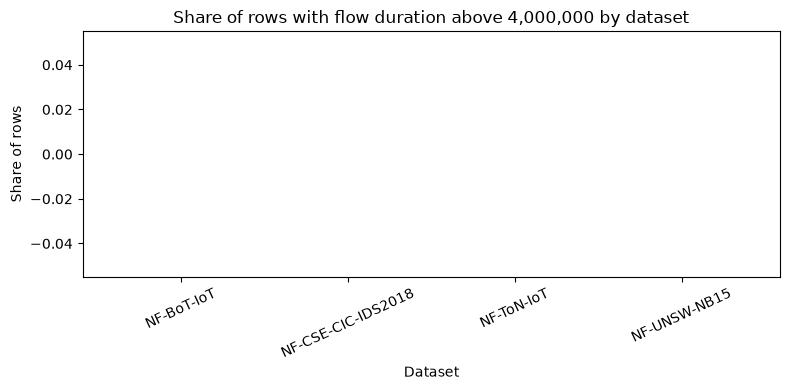

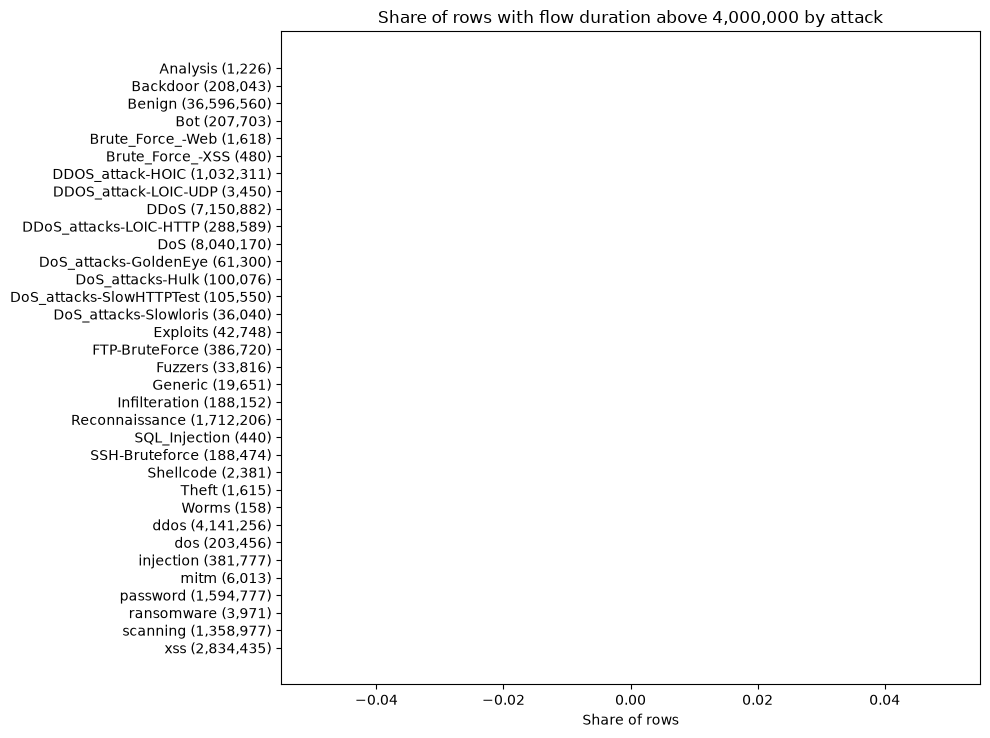

In [33]:
DURATION_TAIL_THRESHOLD = 4000000

duration_by_group = q(f"SELECT Dataset, Attack, COUNT(*) AS rows_total, COUNT(*) FILTER (WHERE FLOW_DURATION_MILLISECONDS > {DURATION_TAIL_THRESHOLD}) AS rows_tail FROM flows GROUP BY Dataset, Attack")
duration_by_group["share"] = duration_by_group["rows_tail"] / duration_by_group["rows_total"]
display(duration_by_group.sort_values("share", ascending=False, kind="stable").reset_index(drop=True))

duration_by_dataset = duration_by_group.groupby("Dataset", as_index=False).agg(rows_total=("rows_total", "sum"), rows_tail=("rows_tail", "sum"))
duration_by_dataset["share"] = duration_by_dataset["rows_tail"] / duration_by_dataset["rows_total"]
duration_by_dataset = duration_by_dataset.sort_values("share", ascending=False, kind="stable")
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(duration_by_dataset["Dataset"], duration_by_dataset["share"])
ax.set_title("Share of rows with flow duration above 4,000,000 by dataset")
ax.set_xlabel("Dataset")
ax.set_ylabel("Share of rows")
ax.tick_params(axis="x", rotation=25)
show_plot(fig)

duration_by_attack = duration_by_group.groupby("Attack", as_index=False).agg(rows_total=("rows_total", "sum"), rows_tail=("rows_tail", "sum"))
duration_by_attack["share"] = duration_by_attack["rows_tail"] / duration_by_attack["rows_total"]
duration_by_attack = duration_by_attack.sort_values("share", ascending=False, kind="stable")
duration_by_attack["attack_label"] = duration_by_attack.apply(lambda row: f"{row['Attack']} ({int(row['rows_total']):,})", axis=1)
fig, ax = plt.subplots(figsize=(10, max(6, 0.22 * len(duration_by_attack))))
ax.barh(duration_by_attack["attack_label"], duration_by_attack["share"])
ax.invert_yaxis()
ax.set_title("Share of rows with flow duration above 4,000,000 by attack")
ax.set_xlabel("Share of rows")
show_plot(fig)

#### Osservazioni

- Nessuna riga supera 4.000.000 ms, in nessun gruppo `Dataset`×`Attack` (`rows_tail` = 0 ovunque). Nella v2 il massimo era 4.294.967 ms e molte classi superavano la soglia: in v3 questa coda non c'è, quindi non si vede un limite di esportazione. Il valore massimo vero della durata in v3 non è stato calcolato.
- La durata 0 (BoT-IoT 6,21%, UNSW-NB15 5,18%, CSE-CIC-IDS2018 e ToN-IoT 0%) è trattata nel capitolo 3.

#### Note per la pulizia

- Nessun intervento sulla coda della durata.

#### Note per l'addestramento

- Se usare `log1p` o un'altra trasformazione della durata si decide in preprocessing, guardando la distribuzione: qui si è controllata solo la coda.

## 6. Correlation

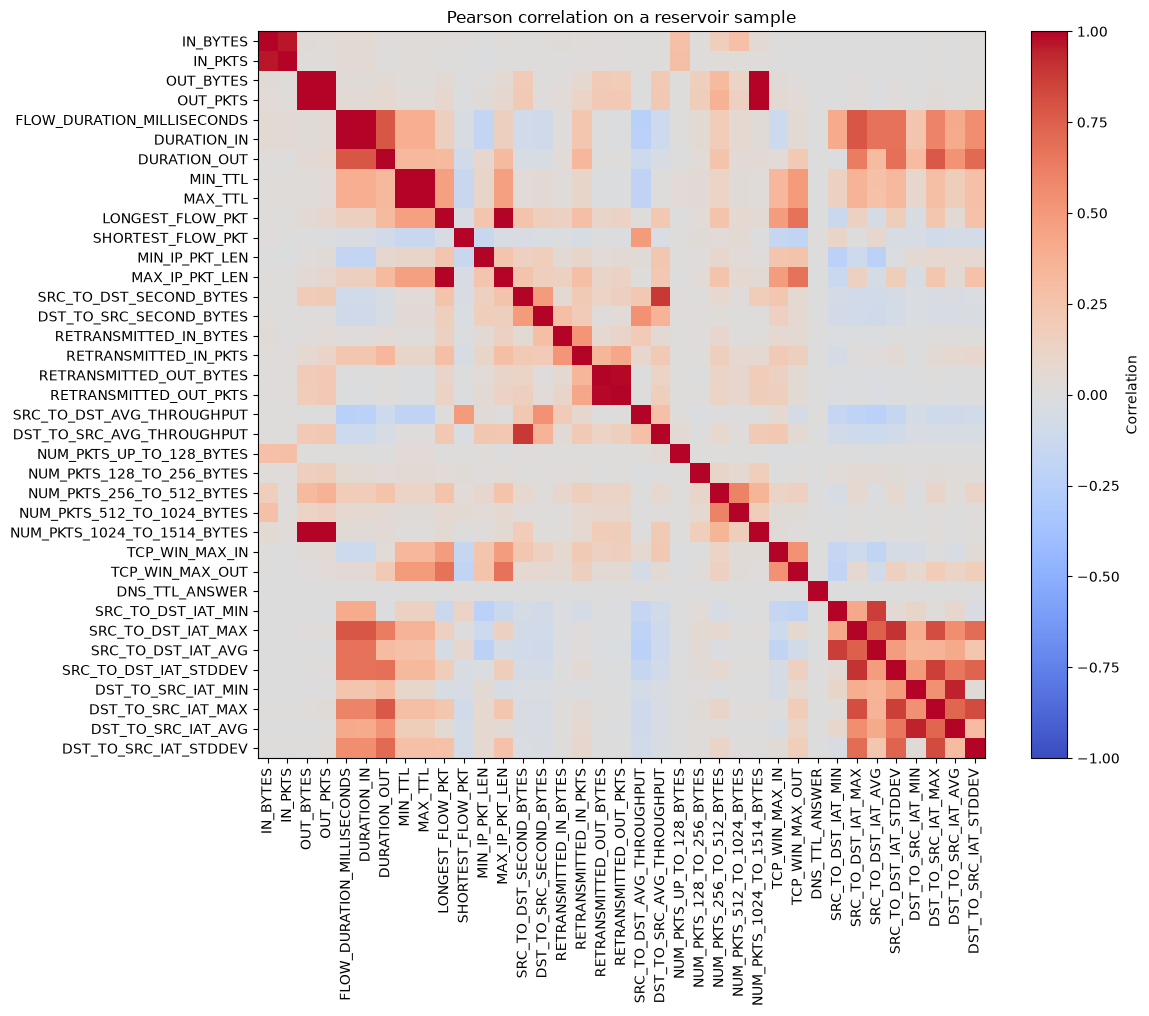

In [34]:
corr_columns = [c for c in continuous if c in ALL_COLUMNS]
correlation_sample = q("SELECT " + ", ".join(sql_ident(c) for c in corr_columns) + " FROM flows USING SAMPLE reservoir(100000 ROWS) REPEATABLE (42)")
corr = correlation_sample.corr(method="pearson")
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("Pearson correlation on a reservoir sample")
fig.colorbar(image, ax=ax, label="Correlation")
show_plot(fig)

In [35]:
correlation_threshold = 0.90
high_correlation_pairs = [(a, b, float(corr.loc[a, b])) for a, b in combinations(corr.columns, 2) if pd.notna(corr.loc[a, b]) and abs(corr.loc[a, b]) >= correlation_threshold]
high_correlation_table = pd.DataFrame(high_correlation_pairs, columns=["feature_a", "feature_b", "pearson_r"]).sort_values("pearson_r", key=lambda values: values.abs(), ascending=False)
display(high_correlation_table)

,feature_a,feature_b,pearson_r
6,LONGEST_FLOW_PKT,MAX_IP_PKT_LEN,1.000000
4,FLOW_DURATION_MILLISECONDS,DURATION_IN,0.999341
5,MIN_TTL,MAX_TTL,0.999009
2,OUT_BYTES,NUM_PKTS_1024_TO_1514_BYTES,0.997491
1,OUT_BYTES,OUT_PKTS,0.995955
3,OUT_PKTS,NUM_PKTS_1024_TO_1514_BYTES,0.994337
7,RETRANSMITTED_OUT_BYTES,RETRANSMITTED_OUT_PKTS,0.991407
0,IN_BYTES,IN_PKTS,0.961944
9,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_AVG,0.944829
8,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_STDDEV,0.901240


In [36]:
class_corr_sample = q("SELECT Label, " + ", ".join(sql_ident(c) for c in corr_columns) + " FROM flows USING SAMPLE reservoir(100000 ROWS) REPEATABLE (42)")
benign_corr = class_corr_sample[class_corr_sample["Label"] == 0][corr_columns].corr()
attack_corr = class_corr_sample[class_corr_sample["Label"] == 1][corr_columns].corr()
correlation_changes = []
for a, b in combinations(corr_columns, 2):
    benign_r, attack_r = benign_corr.loc[a, b], attack_corr.loc[a, b]
    if pd.notna(benign_r) and pd.notna(attack_r):
        correlation_changes.append({"feature_a": a, "feature_b": b, "benign_r": benign_r, "attack_r": attack_r, "absolute_change": abs(attack_r - benign_r)})
class_correlation_changes = pd.DataFrame(correlation_changes).sort_values("absolute_change", ascending=False).head(20)
display(class_correlation_changes)

,feature_a,feature_b,benign_r,attack_r,absolute_change
20,IN_BYTES,NUM_PKTS_UP_TO_128_BYTES,0.000631,0.999782,0.999152
55,IN_PKTS,NUM_PKTS_UP_TO_128_BYTES,0.005879,0.999992,0.994113
23,IN_BYTES,NUM_PKTS_512_TO_1024_BYTES,0.950970,0.007838,0.943132
650,SRC_TO_DST_IAT_MAX,DST_TO_SRC_IAT_STDDEV,0.894871,0.130910,0.763961
126,OUT_PKTS,NUM_PKTS_1024_TO_1514_BYTES,0.995272,0.278613,0.716659
125,OUT_PKTS,NUM_PKTS_512_TO_1024_BYTES,0.144383,0.833245,0.688862
659,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_STDDEV,0.885698,0.197586,0.688112
664,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_STDDEV,0.912853,0.225450,0.687403
326,SHORTEST_FLOW_PKT,NUM_PKTS_128_TO_256_BYTES,-0.003253,0.659408,0.662661
170,DURATION_IN,DURATION_OUT,0.984915,0.337707,0.647208


#### Osservazioni

- Le feature continue sono 37, analizzate su un campione di 100.000 righe (reservoir, seed 42). Il campione è proporzionale alle righe, quindi pesano soprattutto ToN-IoT, CSE-CIC-IDS2018 e BoT-IoT.
- Dieci coppie con |r| ≥ 0,90 (`high_correlation_table`): `LONGEST_FLOW_PKT`–`MAX_IP_PKT_LEN` 1,000; `FLOW_DURATION_MILLISECONDS`–`DURATION_IN` 0,999; `MIN_TTL`–`MAX_TTL` 0,999; `OUT_BYTES`–`NUM_PKTS_1024_TO_1514_BYTES` 0,997; `OUT_BYTES`–`OUT_PKTS` 0,996; `OUT_PKTS`–`NUM_PKTS_1024_TO_1514_BYTES` 0,994; `RETRANSMITTED_OUT_BYTES`–`RETRANSMITTED_OUT_PKTS` 0,991; `IN_BYTES`–`IN_PKTS` 0,962; `DST_TO_SRC_IAT_MIN`–`DST_TO_SRC_IAT_AVG` 0,945; `SRC_TO_DST_IAT_MAX`–`SRC_TO_DST_IAT_STDDEV` 0,901.
- La correlazione cambia molto tra Benign e Attack (`class_correlation_changes`): `IN_BYTES`–`NUM_PKTS_UP_TO_128_BYTES` 0,001 nei Benign contro 0,9998 negli attacchi; `IN_PKTS`–`NUM_PKTS_UP_TO_128_BYTES` 0,006 contro 0,99999; `IN_BYTES`–`NUM_PKTS_512_TO_1024_BYTES` 0,95 contro 0,008. La correlazione globale mescola due regimi diversi.
- Le colonne SECOND_BYTES non compaiono in nessuna coppia. `[ipotesi]` contengono +inf e la cella non li sostituisce con NaN prima del calcolo: le loro correlazioni non sono valide.
- Le correlazioni sono calcolate su tutti i dati insieme: non provano che due colonne siano uguali.

#### Note per la pulizia

- Non togliere colonne solo perché |r| ≥ 0,999: prima si controlla l'uguaglianza riga per riga. Candidate: `LONGEST_FLOW_PKT`/`MAX_IP_PKT_LEN` (r = 1,000), `MIN_TTL`/`MAX_TTL` e `FLOW_DURATION_MILLISECONDS`/`DURATION_IN` (0,999).
- `FLOW_DURATION_MILLISECONDS` e `DURATION_IN` non sono la stessa colonna: la quota di zeri è diversa (in BoT-IoT 6,2% contro 12,0%) e `DURATION_IN` supera la durata del flusso in 11.277 righe. Eventualmente sostituirle con una differenza o un rapporto.
- Le altre coppie (0,90–0,997) descrivono relazioni plausibili: non vanno eliminate in automatico.
- Se SECOND_BYTES restano fuori dalle feature, escluderle anche da `corr_columns` (oppure sostituire ±inf con NaN prima di `.corr()`).

#### Note per l'addestramento

- GNN, LSTM e Transformer tollerano la ridondanza meglio dei modelli lineari: la correlazione serve a ridurre costo e dimensione, non come criterio finale di selezione. Va calcolata solo sul train.
- Visto il cambio di regime tra le classi, ogni selezione basata sulla correlazione globale va confermata con un'ablation.

## 7. Network entities

In [37]:
for c in ["IPV4_SRC_ADDR", "IPV4_DST_ADDR"]:
    if c in ALL_COLUMNS:
        display(q(f"SELECT '{c}' AS feature, COUNT(DISTINCT {sql_ident(c)}) AS distinct_values, COUNT(*) FILTER (WHERE {sql_ident(c)} IS NULL) AS null_count FROM flows"))

,feature,distinct_values,null_count
0,IPV4_SRC_ADDR,197190,0


,feature,distinct_values,null_count
0,IPV4_DST_ADDR,37900,0


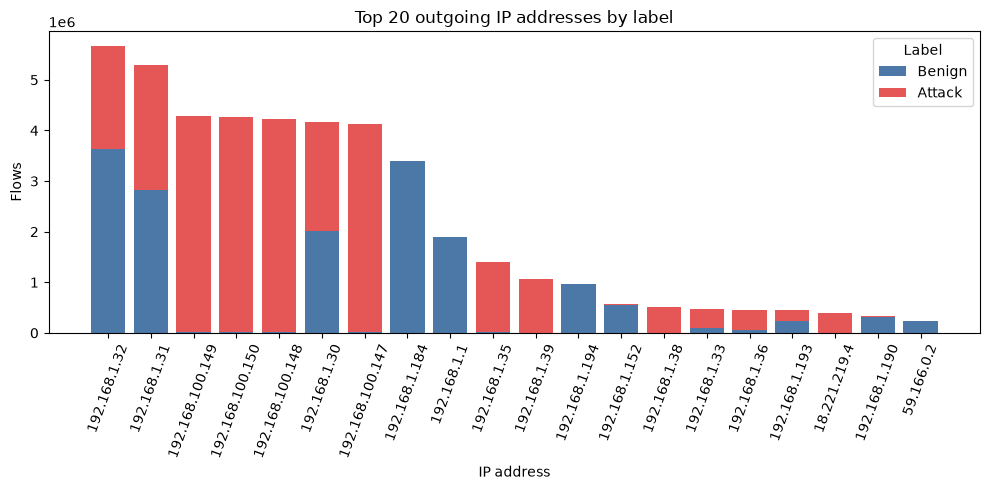

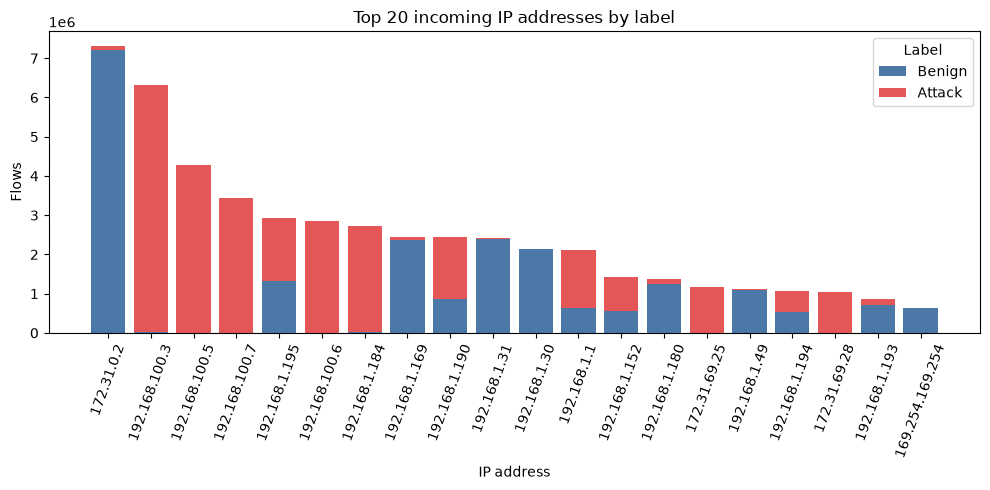

In [38]:
for c, role in [("IPV4_SRC_ADDR", "outgoing"), ("IPV4_DST_ADDR", "incoming")]:
    if c in ALL_COLUMNS:
        top_ips = q(
            f"SELECT {sql_ident(c)} AS ip_address, Label, COUNT(*) AS flows "
            f"FROM flows "
            f"GROUP BY {sql_ident(c)}, Label "
            f"ORDER BY SUM(COUNT(*)) OVER (PARTITION BY {sql_ident(c)}) DESC "
            f"LIMIT 100"
        )

        top_ip_totals = (
            top_ips.groupby("ip_address", as_index=False)["flows"]
            .sum()
            .nlargest(20, "flows")
        )
        top_ip_names = top_ip_totals["ip_address"]
        plot_data = top_ips[top_ips["ip_address"].isin(top_ip_names)]
        plot_data = plot_data.pivot(
            index="ip_address", columns="Label", values="flows"
        ).fillna(0)
        plot_data = plot_data.reindex(top_ip_names)

        fig, ax = plt.subplots(figsize=(10, 5))
        bottom = np.zeros(len(plot_data))

        for label, color, name in [
            (0, "#4C78A8", "Benign"),
            (1, "#E45756", "Attack"),
        ]:
            if label in plot_data.columns:
                ax.bar(
                    plot_data.index.astype(str),
                    plot_data[label],
                    bottom=bottom,
                    color=color,
                    label=name,
                )
                bottom += plot_data[label].to_numpy()

        ax.set_title(f"Top 20 {role} IP addresses by label")
        ax.set_xlabel("IP address")
        ax.set_ylabel("Flows")
        ax.tick_params(axis="x", rotation=70)
        ax.legend(title="Label")
        show_plot(fig)

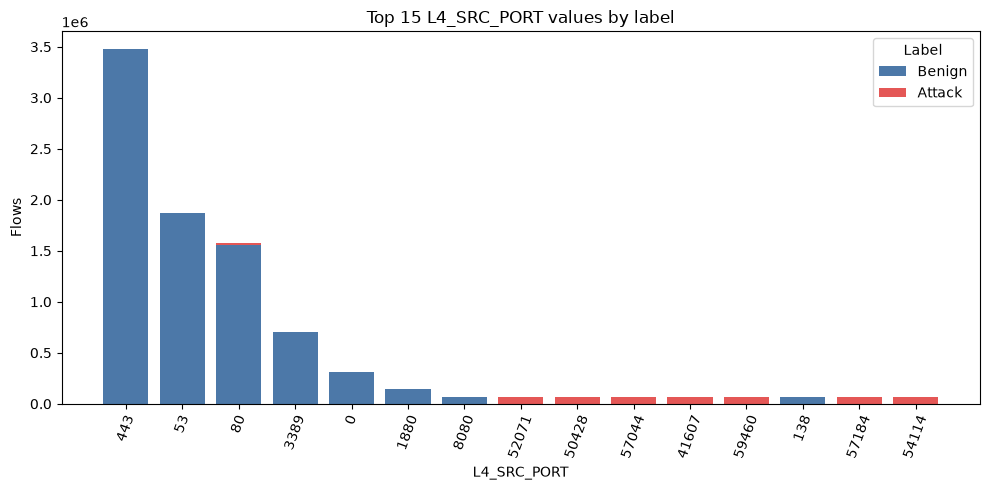

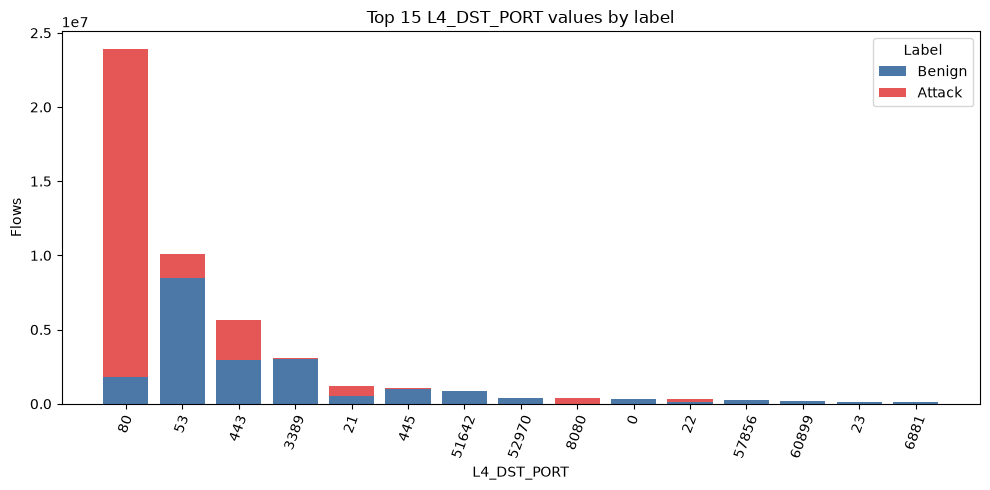

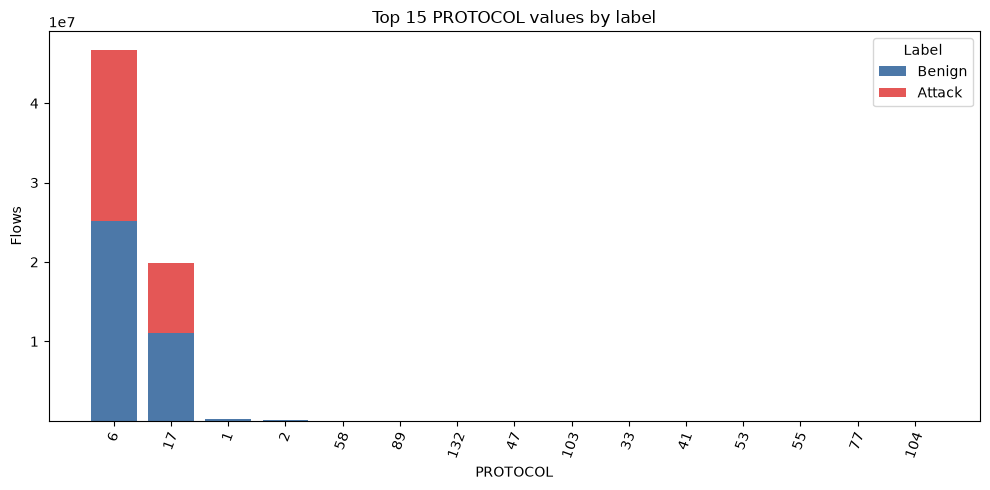

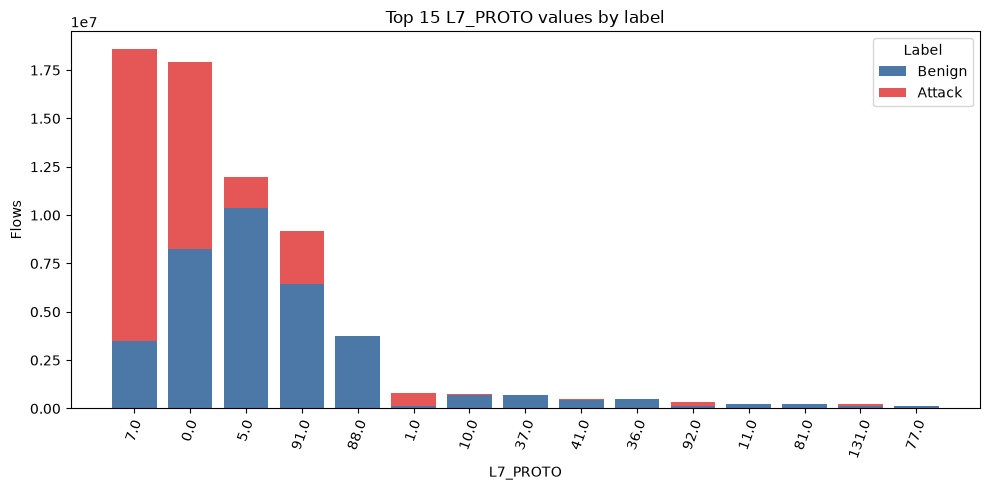

In [39]:
for c in ["L4_SRC_PORT", "L4_DST_PORT", "PROTOCOL", "L7_PROTO"]:
    if c in ALL_COLUMNS:
        port_counts = q(
            f"SELECT {sql_ident(c)} AS value, Label, COUNT(*) AS rows "
            f"FROM flows "
            f"GROUP BY {sql_ident(c)}, Label"
        )

        top_values = (
            port_counts.groupby("value", as_index=False)["rows"]
            .sum()
            .nlargest(15, "rows")["value"]
        )
        plot_data = port_counts[port_counts["value"].isin(top_values)]
        plot_data = plot_data.pivot(
            index="value", columns="Label", values="rows"
        ).fillna(0)
        plot_data = plot_data.reindex(top_values)

        fig, ax = plt.subplots(figsize=(10, 5))
        bottom = np.zeros(len(plot_data))

        for label, color, name in [
            (0, "#4C78A8", "Benign"),
            (1, "#E45756", "Attack"),
        ]:
            if label in plot_data.columns:
                ax.bar(
                    plot_data.index.astype(str),
                    plot_data[label],
                    bottom=bottom,
                    color=color,
                    label=name,
                )
                bottom += plot_data[label].to_numpy()

        ax.set_title(f"Top 15 {c} values by label")
        ax.set_xlabel(c)
        ax.set_ylabel("Flows")
        ax.tick_params(axis="x", rotation=70)
        ax.legend(title="Label")
        show_plot(fig)

In [40]:
if {"IPV4_SRC_ADDR", "IPV4_DST_ADDR", "L4_DST_PORT", "PROTOCOL"}.issubset(ALL_COLUMNS):
    source_ip_summary = q("SELECT IPV4_SRC_ADDR AS source_ip, COUNT(*) AS flows, COUNT(DISTINCT IPV4_DST_ADDR) AS distinct_destinations, COUNT(DISTINCT L4_DST_PORT) AS distinct_destination_ports, COUNT(DISTINCT PROTOCOL) AS distinct_protocols FROM flows GROUP BY IPV4_SRC_ADDR ORDER BY flows DESC LIMIT 100")
    display(source_ip_summary)
# Full-table grouping by source IP may be expensive.

,source_ip,flows,distinct_destinations,distinct_destination_ports,distinct_protocols
0,192.168.1.32,5674551,295,65536,3
1,192.168.1.31,5290458,404,5125,3
2,192.168.100.149,4288975,13,65536,3
3,192.168.100.150,4256405,14,65530,3
4,192.168.100.148,4233290,13,65534,3
5,192.168.1.30,4167103,367,65536,3
6,192.168.100.147,4118881,13,65535,3
7,192.168.1.184,3392370,1481,35367,3
8,192.168.1.1,1892853,18,12422,4
9,192.168.1.35,1398665,46,7,3


In [41]:
ip_class = q("SELECT Dataset, IPV4_SRC_ADDR, COUNT(DISTINCT Label) AS label_count, MIN(Label) AS only_label FROM flows GROUP BY Dataset, IPV4_SRC_ADDR")
ip_shortcut = ip_class.groupby(["Dataset", "label_count"], as_index=False).size().pivot(index="Dataset", columns="label_count", values="size").fillna(0).rename(columns={1: "source_ips_one_label", 2: "source_ips_both_labels"}).reset_index()
if "source_ips_one_label" in ip_shortcut.columns:
    ip_shortcut["source_ips_only_label_0"] = [int(((ip_class.Dataset == d) & (ip_class.label_count == 1) & (ip_class.only_label == 0)).sum()) for d in ip_shortcut.Dataset]
    ip_shortcut["source_ips_only_label_1"] = [int(((ip_class.Dataset == d) & (ip_class.label_count == 1) & (ip_class.only_label == 1)).sum()) for d in ip_shortcut.Dataset]
display(ip_shortcut)
# This full-table aggregation measures potential source-IP shortcut learning.

label_count,Dataset,source_ips_one_label,source_ips_both_labels,source_ips_only_label_0,source_ips_only_label_1
0,NF-BoT-IoT,12.0,8.0,12,0
1,NF-CSE-CIC-IDS2018,180913.0,963.0,180718,195
2,NF-ToN-IoT,15246.0,24.0,15244,2
3,NF-UNSW-NB15,40.0,0.0,36,4


In [42]:
port_class = q("SELECT Dataset, L4_DST_PORT, COUNT(DISTINCT Label) AS label_count, MIN(Label) AS only_label FROM flows GROUP BY Dataset, L4_DST_PORT")
port_shortcut = port_class.groupby(["Dataset", "label_count"], as_index=False).size().pivot(index="Dataset", columns="label_count", values="size").fillna(0).rename(columns={1: "destination_ports_one_label", 2: "destination_ports_both_labels"}).reset_index()
for label in [0, 1]:
    port_shortcut[f"destination_ports_only_label_{label}"] = [int(((port_class.Dataset == d) & (port_class.label_count == 1) & (port_class.only_label == label)).sum()) for d in port_shortcut.Dataset]
display(port_shortcut)
# This full-table aggregation measures potential destination-port shortcut learning.

label_count,Dataset,destination_ports_one_label,destination_ports_both_labels,destination_ports_only_label_0,destination_ports_only_label_1
0,NF-BoT-IoT,57695.0,7841.0,0,57695
1,NF-CSE-CIC-IDS2018,61420.0,1887.0,61418,2
2,NF-ToN-IoT,0.0,65536.0,0,0
3,NF-UNSW-NB15,58957.0,5660.0,58856,101


In [43]:
ip_overlap = q("SELECT IPV4_SRC_ADDR AS ip_address, COUNT(DISTINCT Dataset) AS dataset_count FROM flows GROUP BY IPV4_SRC_ADDR HAVING COUNT(DISTINCT Dataset) > 1")
print(f"Source IPs appearing in multiple datasets: {len(ip_overlap):,}")
display(ip_overlap.groupby("dataset_count").size().rename("source_ips").reset_index())
# Counting distinct IPs across the full table may be expensive.

Source IPs appearing in multiple datasets: 15


,dataset_count,source_ips
0,2,14
1,3,1


#### Osservazioni

- Ci sono 197.190 IP sorgente distinti e 37.900 IP destinazione, senza NULL. Per `Dataset`, gli IP sorgente sono 20 (BoT-IoT), 181.876 (CSE-CIC-IDS2018), 15.270 (ToN-IoT) e 40 (UNSW-NB15). Il traffico è dominato da pochi host privati: `192.168.1.32` con 5,67 milioni di flussi, `192.168.1.31` con 5,29 milioni, `192.168.100.147`–`150` con circa 4,1–4,3 milioni ciascuno.
- IP sorgente e classe (`ip_shortcut`, conteggio per IP, non pesato per flussi): BoT-IoT 12 IP solo Benign, 8 con entrambe le classi e nessuno solo attacco; CSE-CIC-IDS2018 195 solo attacco, 963 entrambe, 180.718 solo Benign; ToN-IoT 2 solo attacco, 24 entrambe, 15.244 solo Benign; UNSW-NB15 4 solo attacco, 36 solo Benign.
- In CSE-CIC-IDS2018 alcune classi di attacco vengono da un solo IP sorgente, con una sola destinazione (`source_ip_summary`): `18.221.219.4` ha 386.720 flussi (come `FTP-BruteForce`), `13.58.98.64` 188.474 (come `SSH-Bruteforce`), `13.59.126.31` 105.550 (come `DoS_attacks-SlowHTTPTest`), `18.219.193.20` 100.076 (come `DoS_attacks-Hulk`). `[ipotesi]` per queste classi l'IP identifica la classe: il numero di flussi coincide con la dimensione della classe.
- Porta di destinazione e classe (`port_shortcut`, valori distinti non pesati): in ToN-IoT tutte le 65.536 porte compaiono con entrambe le classi; in BoT-IoT 57.695 porte compaiono solo negli attacchi, 7.841 in entrambe e nessuna solo nei Benign; in UNSW-NB15 101 porte solo attacco e 58.856 solo Benign; in CSE-CIC-IDS2018 2 solo attacco e 61.418 solo Benign.
- 15 IP sorgente compaiono in più `Dataset` (14 in due, 1 in tre). `[ipotesi]` sono indirizzi privati riutilizzati in reti diverse: gli IP non sono stati stampati.

#### Note per la pulizia

- Niente da correggere. IP e porte vanno trattati come identificatori, non come feature numeriche.

#### Note per l'addestramento

- Escludere `IPV4_SRC_ADDR` e `IPV4_DST_ADDR` dalle feature. Nella GNN gli IP possono definire i nodi (la struttura del grafo), ma l'IP grezzo non deve finire tra gli attributi dei nodi.
- `L4_DST_PORT` come numero può essere una scorciatoia: in BoT-IoT molte porte compaiono solo negli attacchi, ma è un conteggio di valori distinti e BoT-IoT è quasi solo attacco, quindi va verificato. Usare fasce (well-known, registered, ephemeral) o includerla solo in ablation per `Dataset`.
- Provare anche uno split per host (gruppi di IP), oltre allo split temporale. Attenzione: le classi di CSE-CIC-IDS2018 che vengono da un solo IP finirebbero tutte in train o tutte in test.
- Lo stesso IP in sorgenti diverse non è lo stesso host: non costruire grafi o sequenze che attraversino i `Dataset`.

## 8. Timestamp

I timestamp permettono di ricostruire l’ordine temporale utile per LSTM e Transformer e per creare sequenze e finestre. I timestamp v3 potrebbero però contenere errori: vanno validati prima della costruzione delle sequenze e dello split temporale.

In [44]:
time_summary = q("""
SELECT Dataset, epoch_ms(min(FLOW_START_MILLISECONDS)::BIGINT) AS first_start_utc,
 epoch_ms(max(FLOW_START_MILLISECONDS)::BIGINT) AS last_start_utc,
 epoch_ms(min(FLOW_END_MILLISECONDS)::BIGINT) AS first_end_utc,
 epoch_ms(max(FLOW_END_MILLISECONDS)::BIGINT) AS last_end_utc,
 count(DISTINCT CAST(epoch_ms(FLOW_START_MILLISECONDS::BIGINT) AS DATE)) AS utc_days,
 count(*) FILTER (WHERE FLOW_END_MILLISECONDS < FLOW_START_MILLISECONDS) AS end_before_start
FROM flows GROUP BY Dataset ORDER BY Dataset
""")
display(time_summary)

,Dataset,first_start_utc,last_start_utc,first_end_utc,last_end_utc,utc_days,end_before_start
0,NF-BoT-IoT,2018-05-15 00:27:11.665,2018-06-19 04:17:13.932,2018-05-15 00:29:11.932,2018-06-19 04:17:14.508,6,0
1,NF-CSE-CIC-IDS2018,2018-02-14 12:28:07.705,2018-03-02 20:04:25.524,2018-02-14 12:28:07.705,2018-03-02 20:06:24.780,11,0
2,NF-ToN-IoT,2019-04-23 14:09:50.618,2019-04-29 14:45:55.177,2019-04-23 14:09:50.618,2019-04-29 14:45:55.861,7,0
3,NF-UNSW-NB15,2015-01-22 11:49:36.907,2015-02-18 12:29:24.927,2015-01-22 11:50:14.036,2015-02-18 12:29:25.011,3,0


In [45]:
duration_distinct = q("""
SELECT Dataset, count(DISTINCT (FLOW_END_MILLISECONDS - FLOW_START_MILLISECONDS) - FLOW_DURATION_MILLISECONDS) AS differences
FROM flows GROUP BY Dataset
""")
if duration_distinct.differences.max() <= 30:
    duration_diff = q("""
    SELECT Dataset, (FLOW_END_MILLISECONDS - FLOW_START_MILLISECONDS) - FLOW_DURATION_MILLISECONDS AS difference_ms, count(*) AS rows
    FROM flows GROUP BY Dataset, difference_ms ORDER BY Dataset, rows DESC
    """)
else:
    duration_diff = q("""
    SELECT Dataset, floor(((FLOW_END_MILLISECONDS - FLOW_START_MILLISECONDS) - FLOW_DURATION_MILLISECONDS) / 1000) * 1000 AS difference_ms, count(*) AS rows
    FROM flows GROUP BY Dataset, difference_ms ORDER BY Dataset, rows DESC
    """)
# Display the 10 most frequent gaps per dataset.
display(duration_diff.groupby("Dataset", group_keys=False).head(10))

,Dataset,difference_ms,rows
0,NF-BoT-IoT,0,8831845
1,NF-BoT-IoT,1,8101963
2,NF-CSE-CIC-IDS2018,0,9260908
3,NF-CSE-CIC-IDS2018,1,6764378
4,NF-CSE-CIC-IDS2018,-1,4090243
5,NF-ToN-IoT,-1,17005618
6,NF-ToN-IoT,0,5936711
7,NF-ToN-IoT,1,4577931
8,NF-UNSW-NB15,0,1254366
9,NF-UNSW-NB15,1,1111058


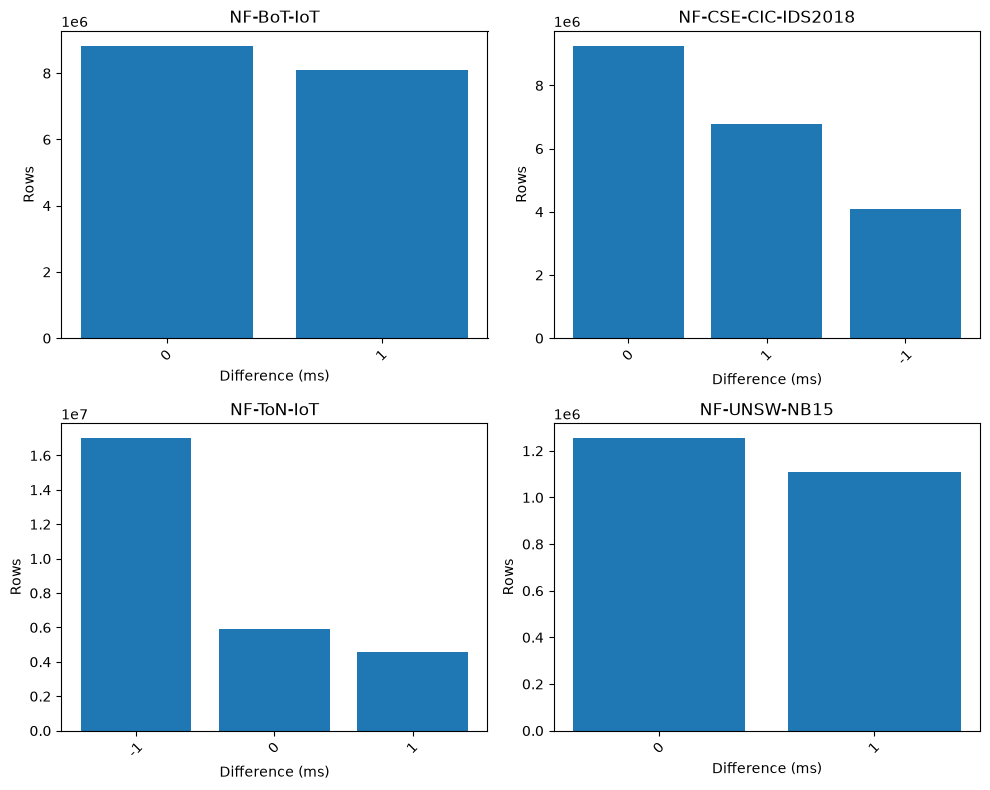

In [46]:
DATASETS = rows_by_dataset["Dataset"].tolist()
duration_top = duration_diff.groupby("Dataset", group_keys=False).head(10)
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, dataset in zip(axes.flat, DATASETS):
    part = duration_top[duration_top.Dataset == dataset]
    ax.bar(part.difference_ms.astype(str), part.rows)
    ax.set_title(dataset)
    ax.set_xlabel("Difference (ms)")
    ax.set_ylabel("Rows")
    ax.tick_params(axis="x", rotation=45)
show_plot(fig)

In [47]:
daily = q("""
SELECT Dataset, CAST(epoch_ms(FLOW_START_MILLISECONDS::BIGINT) AS DATE) AS utc_day,
 CASE WHEN Label = 0 THEN 'Benign' ELSE 'Attack' END AS class, count(*) AS rows
FROM flows GROUP BY Dataset, utc_day, class ORDER BY Dataset, utc_day
""")
display(daily.head(50))  # The daily table may be long; display the first 50 rows.

,Dataset,utc_day,class,rows
0,NF-BoT-IoT,2018-05-15,Attack,124302
1,NF-BoT-IoT,2018-05-15,Benign,13566
2,NF-BoT-IoT,2018-05-21,Attack,781721
3,NF-BoT-IoT,2018-05-21,Benign,20451
4,NF-BoT-IoT,2018-05-22,Benign,14425
5,NF-BoT-IoT,2018-05-22,Attack,789109
6,NF-BoT-IoT,2018-06-04,Benign,3146
7,NF-BoT-IoT,2018-06-04,Attack,15185072
8,NF-BoT-IoT,2018-06-18,Attack,140
9,NF-BoT-IoT,2018-06-18,Benign,148


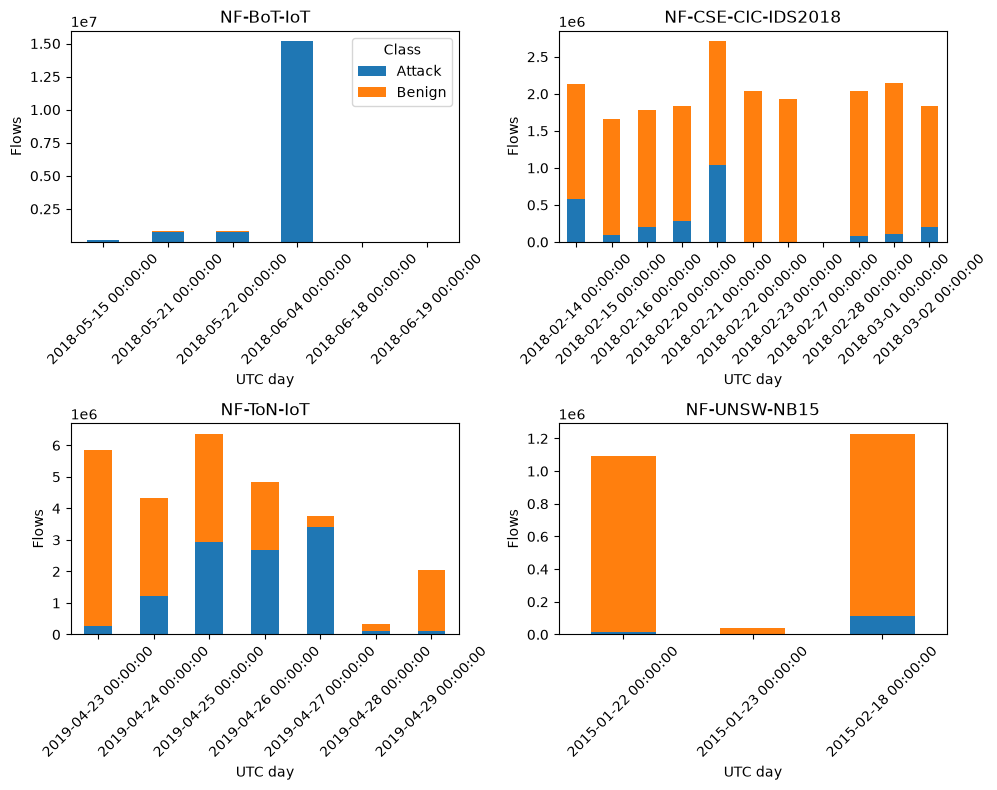

In [48]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, dataset in zip(axes.flat, DATASETS):
    part = daily[daily.Dataset == dataset].pivot(index="utc_day", columns="class", values="rows").fillna(0)
    part.plot(kind="bar", stacked=True, ax=ax, legend=False)
    ax.set_title(dataset)
    ax.set_xlabel("UTC day")
    ax.set_ylabel("Flows")
    ax.tick_params(axis="x", labelrotation=45)
axes[0, 0].legend(title="Class")
show_plot(fig)

In [49]:
attack_windows = q("""
SELECT Dataset, Attack, min(CAST(epoch_ms(FLOW_START_MILLISECONDS::BIGINT) AS DATE)) AS first_day,
 max(CAST(epoch_ms(FLOW_START_MILLISECONDS::BIGINT) AS DATE)) AS last_day,
 count(DISTINCT CAST(epoch_ms(FLOW_START_MILLISECONDS::BIGINT) AS DATE)) AS distinct_days
FROM flows GROUP BY Dataset, Attack ORDER BY Dataset, first_day
""")
display(attack_windows.head(50))  # Display at most 50 time windows.

,Dataset,Attack,first_day,last_day,distinct_days
0,NF-BoT-IoT,Reconnaissance,2018-05-15,2018-05-22,3
1,NF-BoT-IoT,Benign,2018-05-15,2018-06-19,6
2,NF-BoT-IoT,DoS,2018-06-04,2018-06-04,1
3,NF-BoT-IoT,DDoS,2018-06-04,2018-06-04,1
4,NF-BoT-IoT,Theft,2018-06-18,2018-06-19,2
5,NF-CSE-CIC-IDS2018,Benign,2018-02-14,2018-03-02,11
6,NF-CSE-CIC-IDS2018,SSH-Bruteforce,2018-02-14,2018-02-14,1
7,NF-CSE-CIC-IDS2018,FTP-BruteForce,2018-02-14,2018-02-14,1
8,NF-CSE-CIC-IDS2018,DoS_attacks-GoldenEye,2018-02-15,2018-02-15,1
9,NF-CSE-CIC-IDS2018,DoS_attacks-Slowloris,2018-02-15,2018-02-15,1


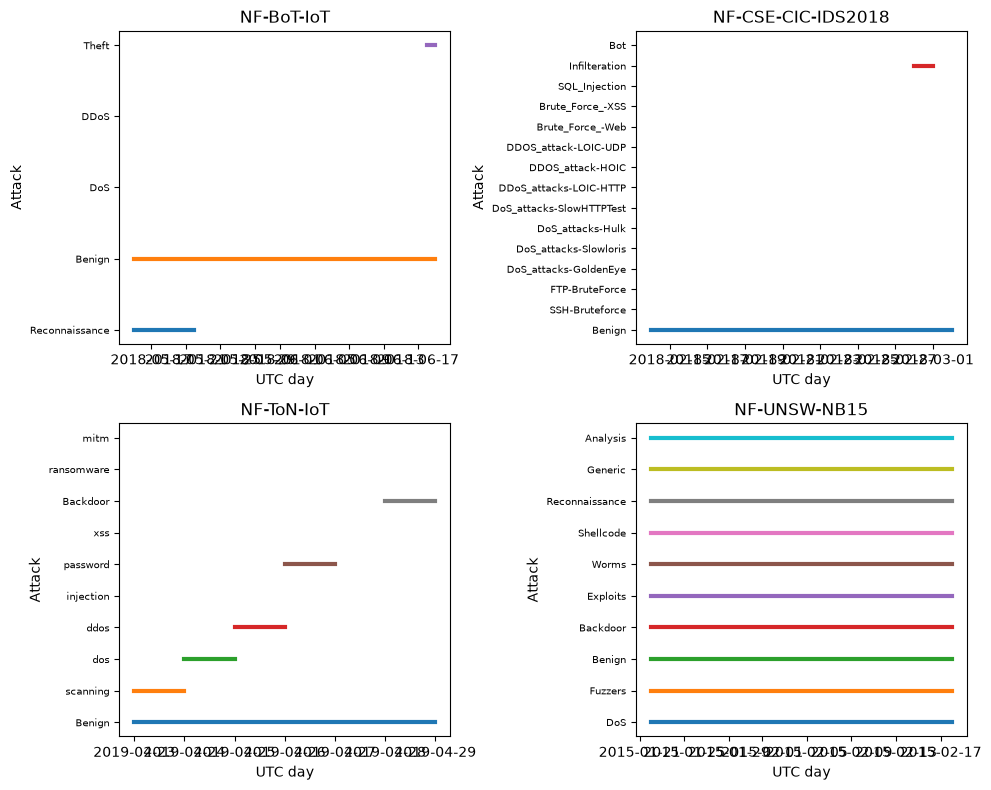

In [50]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, dataset in zip(axes.flat, DATASETS):
    part = attack_windows[attack_windows.Dataset == dataset].sort_values("first_day")
    for y, row in enumerate(part.itertuples()):
        ax.plot([row.first_day, row.last_day], [y, y], linewidth=3)
    ax.set_title(dataset)
    ax.set_xlabel("UTC day")
    ax.set_ylabel("Attack")
    ax.set_yticks(range(len(part)))
    ax.set_yticklabels(part.Attack, fontsize=7)
show_plot(fig)

In [51]:
# One Dataset at a time to limit memory use.
row_time_order_parts = []
for dataset in rows_by_dataset["Dataset"]:
    dataset_sql = str(dataset).replace("'", "''")
    dataset_order = q(f"""
    WITH ordered AS (
        SELECT Dataset, row_id, FLOW_START_MILLISECONDS,
               LAG(FLOW_START_MILLISECONDS) OVER (PARTITION BY Dataset ORDER BY row_id) AS previous_start
        FROM flows
        WHERE Dataset = '{dataset_sql}'
    )
    SELECT Dataset, COUNT(*) FILTER (WHERE previous_start IS NOT NULL) AS consecutive_pairs,
           COUNT(*) FILTER (WHERE previous_start IS NOT NULL AND FLOW_START_MILLISECONDS >= previous_start) AS in_order_pairs,
           COUNT(*) FILTER (WHERE previous_start IS NOT NULL AND FLOW_START_MILLISECONDS < previous_start) AS inversions
    FROM ordered GROUP BY Dataset
    """)
    row_time_order_parts.append(dataset_order)
row_time_order = pd.concat(row_time_order_parts, ignore_index=True)
row_time_order["in_order_share"] = row_time_order["in_order_pairs"] / row_time_order["consecutive_pairs"]
display(row_time_order)


,Dataset,consecutive_pairs,in_order_pairs,inversions,in_order_share
0,NF-BoT-IoT,16933807,16893071,40736,0.997594
1,NF-CSE-CIC-IDS2018,20115528,20115527,1,1.000000
2,NF-ToN-IoT,27520259,27520259,0,1.000000
3,NF-UNSW-NB15,2365423,2029980,335443,0.858189


In [52]:
timestamp_range = q("""
SELECT Dataset, 'FLOW_START_MILLISECONDS' AS feature, COUNT(*) AS rows,
       COUNT(*) FILTER (WHERE FLOW_START_MILLISECONDS <= 0) AS non_positive,
       COUNT(*) FILTER (WHERE FLOW_START_MILLISECONDS <= 0 OR length(CAST(FLOW_START_MILLISECONDS AS VARCHAR)) <> 13) AS implausible
FROM flows GROUP BY Dataset
UNION ALL
SELECT Dataset, 'FLOW_END_MILLISECONDS' AS feature, COUNT(*) AS rows,
       COUNT(*) FILTER (WHERE FLOW_END_MILLISECONDS <= 0) AS non_positive,
       COUNT(*) FILTER (WHERE FLOW_END_MILLISECONDS <= 0 OR length(CAST(FLOW_END_MILLISECONDS AS VARCHAR)) <> 13) AS implausible
FROM flows GROUP BY Dataset
ORDER BY Dataset, feature
""")
display(timestamp_range)


,Dataset,feature,rows,non_positive,implausible
0,NF-BoT-IoT,FLOW_END_MILLISECONDS,16933808,0,0
1,NF-BoT-IoT,FLOW_START_MILLISECONDS,16933808,0,0
2,NF-CSE-CIC-IDS2018,FLOW_END_MILLISECONDS,20115529,0,0
3,NF-CSE-CIC-IDS2018,FLOW_START_MILLISECONDS,20115529,0,0
4,NF-ToN-IoT,FLOW_END_MILLISECONDS,27520260,0,0
5,NF-ToN-IoT,FLOW_START_MILLISECONDS,27520260,0,0
6,NF-UNSW-NB15,FLOW_END_MILLISECONDS,2365424,0,0
7,NF-UNSW-NB15,FLOW_START_MILLISECONDS,2365424,0,0


#### Osservazioni

- Intervalli UTC (`time_summary`): BoT-IoT dal 2018-05-15 al 2018-06-19 (6 giorni con dati), CSE-CIC-IDS2018 dal 2018-02-14 al 2018-03-02 (11 giorni), ToN-IoT dal 2019-04-23 al 2019-04-29 (7 giorni), UNSW-NB15 dal 2015-01-22 al 2015-02-18 (3 giorni: 22 e 23 gennaio, 18 febbraio, cioè due sessioni a circa 26 giorni di distanza). I periodi sono diversi e non si sovrappongono: le sorgenti non condividono una linea temporale.
- Nessuna riga ha `FLOW_END` < `FLOW_START` e non ci sono NULL; tutti i timestamp sono positivi e a 13 cifre (`timestamp_range`: 0 non positivi, 0 implausibili).
- Lo scarto (`FLOW_END` − `FLOW_START`) − `FLOW_DURATION_MILLISECONDS` vale solo −1, 0 o +1 ms in tutte le sorgenti (`duration_diff`), compatibile con un arrotondamento al millisecondo. −1 è il valore più frequente in ToN-IoT (17,0 milioni di righe, 61,8%) ed è presente anche in CSE-CIC-IDS2018 (4,09 milioni, 20,3%); BoT-IoT e UNSW-NB15 non lo hanno. `[ipotesi]` in CSE-CIC-IDS2018 e ToN-IoT la durata minima è 1 ms anche per i flussi con inizio e fine uguali (capitolo 3), e questo spiega il −1.
- Ordine di `row_id` rispetto a `FLOW_START` (`row_time_order`): ToN-IoT 0 inversioni, CSE-CIC-IDS2018 1, BoT-IoT 40.736 (0,24% delle coppie consecutive), UNSW-NB15 335.443 (14,2%: solo l'85,8% delle coppie è in ordine). Quindi `row_id` è cronologico in ToN-IoT e CSE-CIC-IDS2018, quasi cronologico in BoT-IoT e non cronologico in UNSW-NB15.
- Copertura temporale (`daily`, `attack_windows`): in BoT-IoT `DoS` e `DDoS` compaiono solo il 2018-06-04 (15,19 milioni di righe d'attacco, circa il 90% degli attacchi della sorgente), `Reconnaissance` tra il 15 e il 22 maggio e `Theft` solo il 18–19 giugno. In CSE-CIC-IDS2018 ogni attacco sta in un solo giorno (`Infilteration` in due) mentre il Benign c'è in tutti gli 11 giorni. In ToN-IoT ogni attacco occupa 1–2 giorni e il Benign tutti e 7. In UNSW-NB15 tutte le classi compaiono nelle due sessioni, con 17.462 attacchi il 22 gennaio e 110.231 il 18 febbraio.

#### Note per la pulizia

- Non c'è nessuna riga da eliminare per i timestamp: nessun intervallo invertito, nessun valore fuori scala, nessun NULL. Lo scarto di ±1 ms non va corretto.
- I controlli verificano la coerenza interna (inizio/fine, durata), non la correttezza assoluta di fuso e offset.

#### Note per l'addestramento

- Per costruire sequenze o finestre, ordinare per `Dataset` e `FLOW_START_MILLISECONDS` (a parità, `row_id`). Non usare `row_id` come ordine: è affidabile solo in ToN-IoT e CSE-CIC-IDS2018 (UNSW-NB15 14,2% di inversioni, BoT-IoT 0,24%).
- Non costruire sequenze che attraversino sorgenti diverse. In UNSW-NB15 e BoT-IoT interrompere la sequenza quando il salto temporale supera una soglia (le sessioni sono separate da giorni o settimane); la soglia va scelta guardando i salti reali, che qui non sono stati misurati.
- Uno split per giorni interi non funziona: toglierebbe intere classi di attacco da train o test (in CSE-CIC-IDS2018 e ToN-IoT ogni attacco sta in 1–2 giorni; in BoT-IoT `DoS` e `DDoS` solo il 4 giugno). Opzioni: split temporale dentro ogni episodio (per `Dataset`×`Attack`, primi X% del tempo in train e ultimi in test) con un intervallo di separazione (purge) per non condividere finestre; blocchi contigui per classe. Lo split casuale va bene solo come baseline sui singoli flussi, non per le sequenze.
- Le finestre non devono attraversare i confini tra gli split.